# SoundScape AI — Nature Generator


**Natural, calming, controllable soundscapes · End-to-end generative audio pipeline**


[Dataset](https://github.com/karolpiczak/ESC-50)

[pre-training model](https://huggingface.co/cvssp/audioldm2)


In this notebook, we use a **pretrained text-conditioned latent diffusion model (AudioLDM 2)** for audio generation. It also audits real recordings from **ESC-50**, compares original and generated audio, applies gentle mastering, creates seamless longer scenes, and exports a platform-ready WAV library with a JSON manifest.

## 1.Environment setup

In [ ]:
%pip install -q "diffusers==0.42.1" "transformers==5.22.1" "huggingface-hub==1.33.0" "tokenizers==0.23.3" "librosa==0.11.0" "accelerate==1.15.0" "soundfile" "sentencepiece" "safetensors" "jedi>=0.16"

import os, json, gc, random, subprocess, warnings, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import librosa, soundfile as sf
from scipy.signal import resample_poly
import torch
from IPython.display import Audio, display

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
OUTPUT=Path('soundscape_export'); OUTPUT.mkdir(exist_ok=True)
SR=16000
MODEL_ID='cvssp/audioldm2'
MODEL_REVISION='c8e7e189d324425c05c4c2f81214041ef4107983'
print('Device:',DEVICE,'| PyTorch:',torch.__version__)
if DEVICE=='cuda': print('GPU:',torch.cuda.get_device_name(0))

## 2.Method and reproducibility

**AudioLDM 2** combines text encoders and a language model for conditioning with a latent diffusion U-Net, a variational autoencoder and a vocoder.
Denoising is pretrained inference; no weights are updated here. **CVAEs** trained on 200 clips and **Griffin-Lim** are weak baselines for realistic audio. **AudioLDM** is another latent-diffusion baseline; **MusicGen** is geared toward music.






##3.Dataset: ESC-50

The reference dataset provides **40 five-second clips per class**, which is insufficient to train a high-fidelity sound generator from scratch. We therefore use it for transparent audio inspection and comparison, while **generation comes from the pretrained diffusion model**.

**Sound classes:** rain, sea waves, wind, flowing water, distant thunder.

The default prompts favor quiet, continuous ambience. No city noise or abrupt effects.


In [ ]:
CLASSES=['rain','sea_waves','wind','pouring_water','thunderstorm']
ROOT=Path('ESC-50')
if not (ROOT/'meta/esc50.csv').exists():
    subprocess.run(['git','clone','--depth','1','https://github.com/karolpiczak/ESC-50.git'],check=True)
meta=pd.read_csv(ROOT/'meta/esc50.csv')
meta=meta[meta.category.isin(CLASSES)].copy().reset_index(drop=True)
meta['path']=meta.filename.map(lambda x:str(ROOT/'audio'/x))
assert len(meta)==200 and meta.path.map(os.path.isfile).all()
display(meta.groupby(['category','fold']).size().unstack(fill_value=0))
print('Original recordings:',len(meta))

In [ ]:
# Folds 1-3 train, 4 validation, 5 test
meta['split'] = meta.fold.map({1:'train', 2:'train', 3:'train', 4:'validation', 5:'test'})
assert meta.groupby('src_file')['split'].nunique().max() == 1
import hashlib
meta['sha256'] = meta.path.map(lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest())
duplicates = meta[meta.duplicated('sha256', keep=False)]
cross_split = duplicates.groupby('sha256')['split'].nunique()
print('Exact duplicate files:', len(duplicates), '| crossing splits:', int((cross_split > 1).sum()))
assert not (cross_split > 1).any(), 'Exact duplicate across splits'
display(pd.crosstab(meta.category, meta.split))
print('This audit does not rule out near duplicates or pretrained-model contamination.')

##4.Audio audit and listening

Duration and silence are measured independently. Quiet sections may be valid acoustic content, particularly in water or distant-thunder recordings. No clips will be removed automatically.

rms        quiet_ratio        clipping_ratio       
                mean    max        mean    max           mean    max
category                                                            
pouring_water  0.034  0.164       0.195  0.754          0.000  0.001
rain           0.085  0.188       0.000  0.003          0.000  0.000
sea_waves      0.104  0.171       0.011  0.396          0.000  0.000
thunderstorm   0.126  0.525       0.004  0.141          0.008  0.131
wind           0.139  0.570       0.000  0.000          0.003  0.082

,category,filename,fold,duration_s,rms,peak,rms_dbfs,quiet_ratio,clipping_ratio
32,pouring_water,1-61221-A-17.wav,1,5.0,0.063281,0.781255,-23.974571,0.753994,0.0
35,pouring_water,1-67152-A-17.wav,1,5.0,0.008494,0.159427,-41.417887,0.546326,0.0
47,pouring_water,2-102414-G-17.wav,2,5.0,0.023636,0.399512,-32.528526,0.546326,0.0
145,pouring_water,4-172377-A-17.wav,4,5.0,0.004999,0.093236,-46.022096,0.536741,0.0
44,pouring_water,2-102414-D-17.wav,2,5.0,0.005809,0.117262,-44.718145,0.466454,0.0
185,pouring_water,5-207781-A-17.wav,5,5.0,0.020163,0.361743,-33.908812,0.428115,0.0
117,sea_waves,3-187710-A-11.wav,3,5.0,0.062036,0.603796,-24.147128,0.396166,0.0
43,pouring_water,2-102414-C-17.wav,2,5.0,0.010079,0.228293,-39.931813,0.361022,0.0
90,pouring_water,3-127874-A-17.wav,3,5.0,0.019353,0.426563,-34.265034,0.361022,0.0
24,pouring_water,1-50688-A-17.wav,1,5.0,0.005671,0.130353,-44.926778,0.338658,0.0


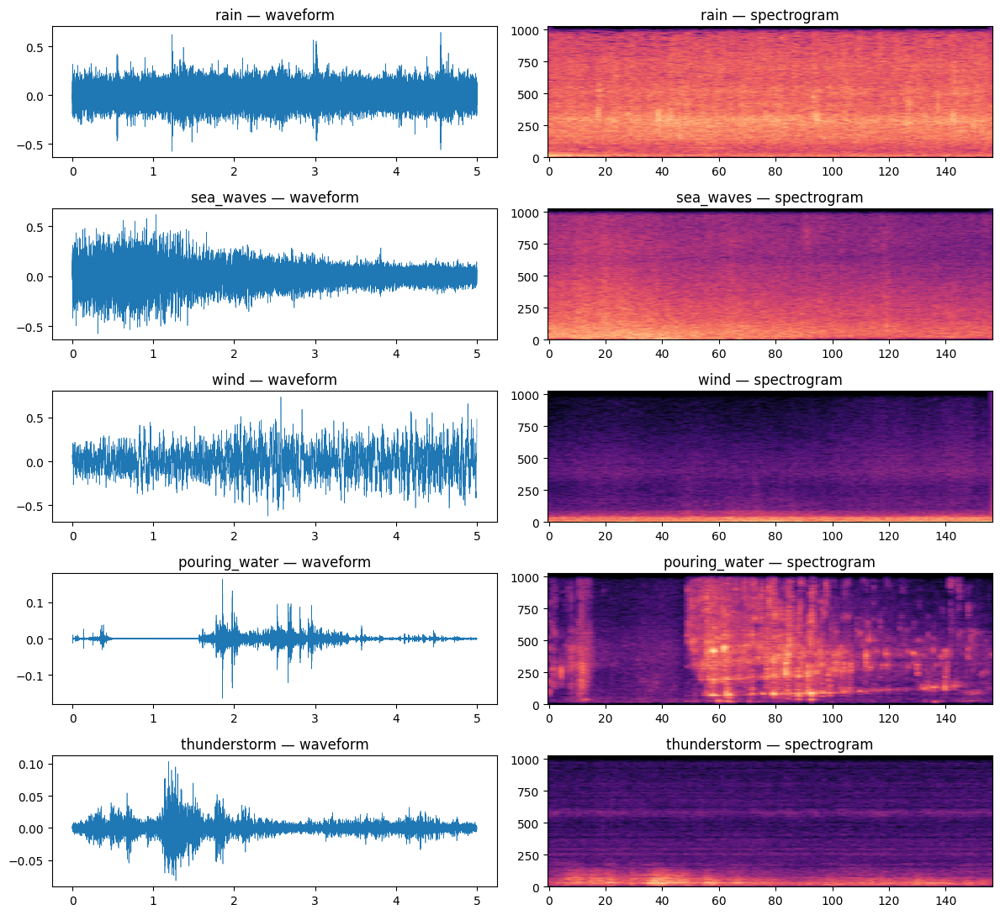

Reference: rain


Reference: sea_waves


Reference: wind


Reference: pouring_water


Reference: thunderstorm


In [4]:
def read_audio(path, sr=SR):
    y,_=librosa.load(str(path),sr=sr,mono=True)
    return np.nan_to_num(y).astype(np.float32)

def audio_metrics(y,sr=SR):
    y=np.asarray(y,dtype=np.float32)
    if len(y)==0:return dict(duration_s=0,rms=0,peak=0,quiet_ratio=1,clipping_ratio=0)
    rms_frames=librosa.feature.rms(y=y,frame_length=1024,hop_length=256)[0]
    return dict(duration_s=round(len(y)/sr,3),rms=float(np.sqrt(np.mean(y*y))),
        peak=float(np.max(np.abs(y))),rms_dbfs=float(20*np.log10(max(float(np.sqrt(np.mean(y*y))),1e-12))),quiet_ratio=float(np.mean(rms_frames<0.001)),
        clipping_ratio=float(np.mean(np.abs(y)>=0.999)))

rows=[]
for row in meta.itertuples():
    rows.append(dict(category=row.category,filename=row.filename,fold=row.fold,
                     **audio_metrics(read_audio(row.path))))
audit=pd.DataFrame(rows)
display(audit.groupby('category')[['rms','quiet_ratio','clipping_ratio']].agg(['mean','max']).round(3))
display(audit.sort_values('quiet_ratio',ascending=False).head(10))
audit.to_csv(OUTPUT/'esc50_audio_audit.csv',index=False)
fig,axes=plt.subplots(len(CLASSES),2,figsize=(12,11))
for i,name in enumerate(CLASSES):
    path=meta.loc[meta.category.eq(name),'path'].iloc[0]; y=read_audio(path)
    axes[i,0].plot(np.arange(len(y))/SR,y,lw=.45);axes[i,0].set_title(name+' — waveform')
    spec=librosa.amplitude_to_db(np.abs(librosa.stft(y)),ref=np.max)
    axes[i,1].imshow(spec,aspect='auto',origin='lower',cmap='magma',vmin=-80,vmax=0)
    axes[i,1].set_title(name+' — spectrogram')
plt.tight_layout();plt.show()
for name in CLASSES:
    path=meta.loc[meta.category.eq(name),'path'].iloc[0]
    print('Reference:',name);display(Audio(filename=path))

## EDA: understanding the 200 ESC-50 clips

The audit above already measured loudness, silence and clipping for every clip and showed one example per class. Before generating or fine-tuning anything, we want to understand the data better to know:

- how many clips we have and how they are split
- what format the original files have (sample rate, channels, length)
- whether some clips are padded with empty silence at the end
- how loud, bright and "spiky" each class is (we will use these numbers later to build the intensity and comfort labels for fine-tuning)



### Dataset size: clips per class and per split

In [ ]:
EXTRA = OUTPUT / "extra"
EXTRA.mkdir(exist_ok=True)

# Count the clips per class and per split (train = folds 1-3, validation = fold 4, test = fold 5)
print("Total clips:", len(meta))
print("Number of classes:", meta.category.nunique())

size_table = pd.crosstab(meta.category, meta.split)
size_table["total"] = size_table.sum(axis=1)
display(size_table)

# Bar chart of the same table
size_table[["train", "validation", "test"]].plot(kind="bar", stacked=True, figsize=(9, 4))
plt.title("Number of clips per class and split")
plt.ylabel("number of clips")
plt.xticks(rotation=0)
plt.legend(title="split", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
#The audit loads every clip at 16 kHz mono because that is what the model uses.
format_rows = []
for row in meta.itertuples():
    info = sf.info(row.path)
    format_rows.append(dict(category=row.category, filename=row.filename,
                            sample_rate=info.samplerate, channels=info.channels,
                            frames=info.frames, duration_s=info.frames / info.samplerate))
format_table = pd.DataFrame(format_rows)

print("Original sample rates (Hz):", sorted(format_table.sample_rate.unique()))
print("Number of channels:", sorted(format_table.channels.unique()))
print("Shortest clip:", format_table.duration_s.min(), "seconds")
print("Longest clip:", format_table.duration_s.max(), "seconds")
print("Clips that are not exactly 5 seconds:", int((format_table.duration_s != 5.0).sum()))
print("Sample rate used in this notebook:", SR, "Hz")

### Padded silence at the end of clips

Every ESC-50 clip is exactly 5 seconds long, but some of them were shorter originally, so we filled them with digital silence (zeros).




In [ ]:
def trailing_zero_seconds(path):
    y, native_sr = sf.read(path, dtype="float32")
    non_zero_positions = np.nonzero(y)[0]
    if len(non_zero_positions) == 0:
        return len(y) / native_sr
    last_sound_sample = non_zero_positions[-1]
    return (len(y) - 1 - last_sound_sample) / native_sr

meta["padded_s"] = [trailing_zero_seconds(p) for p in meta.path]
meta["effective_s"] = 5.0 - meta["padded_s"]

padded_clips = meta[meta.padded_s > 0.05]
print("Clips with more than 0.05 s of padded silence:", len(padded_clips), "out of", len(meta))
display(meta.groupby("category")["padded_s"].agg(["mean", "max"]).round(2))
display(padded_clips.sort_values("padded_s", ascending=False)[["category", "filename", "padded_s", "effective_s"]].head(10))

In [ ]:
# Real sound length (without the padding) for each class
lengths_per_class = [meta.loc[meta.category == c, "effective_s"] for c in CLASSES]

plt.figure(figsize=(8, 4))
plt.boxplot(lengths_per_class)
plt.xticks(range(1, len(CLASSES) + 1), CLASSES)
plt.title("Real sound length per class (5 s minus padded silence)")
plt.ylabel("seconds")
plt.tight_layout()
plt.show()

### Loudness per class

RMS in dBFS is the average loudness of a clip (0 dB is the loudest possible, more negative is quieter).




In [ ]:
loudness_per_class = [audit.loc[audit.category == c, "rms_dbfs"] for c in CLASSES]

plt.figure(figsize=(8, 4))
plt.boxplot(loudness_per_class)
plt.xticks(range(1, len(CLASSES) + 1), CLASSES)
plt.title("Loudness (RMS dBFS) per class")
plt.ylabel("dBFS (higher = louder)")
plt.tight_layout()
plt.show()

display(audit.groupby("category")["rms_dbfs"].agg(["min", "mean", "max"]).round(1))

### Silence and clipping per class

- **Quiet ratio**: the share of short frames that are almost silent. A high value can mean empty padding or a really soft recording.
- **Clipping ratio**: the share of samples at full scale. Clipping means the recording was distorted.

In [ ]:
quiet_per_class = audit.groupby("category")["quiet_ratio"].mean()
clipping_per_class = audit.groupby("category")["clipping_ratio"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(quiet_per_class.index, quiet_per_class.values)
axes[0].set_title("Average quiet ratio")
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(clipping_per_class.index, clipping_per_class.values)
axes[1].set_title("Average clipping ratio")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print("Clips with any clipping:", int((audit.clipping_ratio > 0).sum()))
print("Clips with more than 1% clipped samples:", int((audit.clipping_ratio > 0.01).sum()))

# How much of the quiet ratio comes from the padded silence found above?
audit_with_padding = audit.merge(meta[["filename", "padded_s"]], on="filename")
has_padding = audit_with_padding.padded_s > 0.05
print("Average quiet ratio of clips WITH padded silence:", round(audit_with_padding.loc[has_padding, "quiet_ratio"].mean(), 3))
print("Average quiet ratio of clips WITHOUT padded silence:", round(audit_with_padding.loc[~has_padding, "quiet_ratio"].mean(), 3))

### Extra features for every clip

These are the numbers we will use later to decide which clips are "light or heavy" and "calm or harsh". we measure them only on the real sound part of each clip (padding removed).

- **RMS**: average loudness.
- **Spectral centroid**: where the energy sits in frequency. A higher value means a brighter, sharper sound.
- **Crest factor**: peak divided by RMS. A high value means short loud spikes.
- **Dynamic range**: difference in dB between the loud and quiet moments of the clip (95th and 5th percentile of the frame loudness). A high value means the loudness jumps around.

In [ ]:
def clip_features(y, sr=SR):
    # Simple loudness and sharpness numbers for one waveform
    rms = float(np.sqrt(np.mean(y * y)))
    peak = float(np.max(np.abs(y)))
    centroid = float(np.mean(librosa.feature.spectral_centroid(y=y, sr=sr)))
    frame_rms = librosa.feature.rms(y=y, frame_length=1024, hop_length=256)[0]
    frame_db = 20 * np.log10(frame_rms + 1e-6)
    dynamic_range = float(np.percentile(frame_db, 95) - np.percentile(frame_db, 5))
    return dict(rms=rms, rms_dbfs=20 * np.log10(max(rms, 1e-8)),
                crest_factor=peak / max(rms, 1e-8),
                centroid_hz=centroid, dynamic_range_db=dynamic_range)

feature_rows = []
for row in meta.itertuples():
    y = read_audio(row.path)
    real_end = max(int(row.effective_s * SR), SR)
    feature_rows.append(dict(filename=row.filename, **clip_features(y[:real_end])))

features = pd.DataFrame(feature_rows)
features.to_csv(EXTRA / "esc50_clip_features.csv", index=False)

features_with_class = features.merge(meta[["filename", "category"]], on="filename")
display(features_with_class.groupby("category")[["rms_dbfs", "centroid_hz", "crest_factor", "dynamic_range_db"]].mean().round(2))

In [ ]:
# Brightness (spectral centroid) per class
centroid_per_class = [features_with_class.loc[features_with_class.category == c, "centroid_hz"] for c in CLASSES]

plt.figure(figsize=(8, 4))
plt.boxplot(centroid_per_class)
plt.xticks(range(1, len(CLASSES) + 1), CLASSES)
plt.title("Spectral centroid per class (higher = brighter sound)")
plt.ylabel("Hz")
plt.tight_layout()
plt.show()

In [ ]:
# Spiky sounds (high crest factor) versus sounds with big loudness jumps (high dynamic range)
plt.figure(figsize=(7, 5))
for class_name in CLASSES:
    part = features_with_class[features_with_class.category == class_name]
    plt.scatter(part.dynamic_range_db, part.crest_factor, label=class_name, alpha=0.7)

plt.xlabel("dynamic range (dB)")
plt.ylabel("crest factor (peak / RMS)")
plt.title("Clip sharpness: each dot is one clip")
plt.legend()
plt.tight_layout()
plt.show()

### Average frequency content per class

For every class, we take the log-mel spectrogram of each clip, average it over time, and then average over all clips of the class. The curve shows which frequencies dominate that sound.

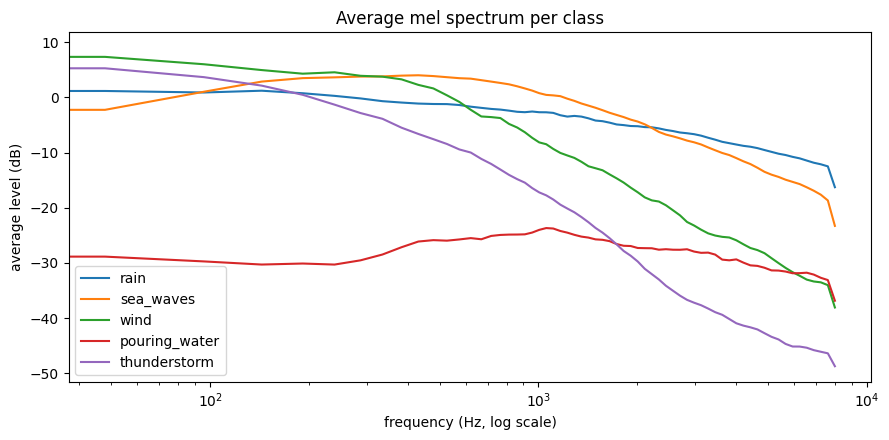

In [14]:
mel_frequencies = librosa.mel_frequencies(n_mels=64, fmax=SR / 2)

plt.figure(figsize=(9, 4.5))
for class_name in CLASSES:
    class_curves = []
    for row in meta[meta.category == class_name].itertuples():
        y = read_audio(row.path)
        y = y[:max(int(row.effective_s * SR), SR)]   # remove the padded silence, it would pull the average down
        mel = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=64)
        mel_db = librosa.power_to_db(mel, ref=1.0)
        class_curves.append(mel_db.mean(axis=1))
    plt.plot(mel_frequencies, np.mean(class_curves, axis=0), label=class_name)

plt.xscale("log")
plt.xlabel("frequency (Hz, log scale)")
plt.ylabel("average level (dB)")
plt.title("Average mel spectrum per class")
plt.legend()
plt.tight_layout()
plt.show()

### Quietest and loudest clip of each class

Here we check the "light / heavy" idea. If the loudest and quietest clips of a class really look and sound different, loudness is a usable stand-in for intensity.

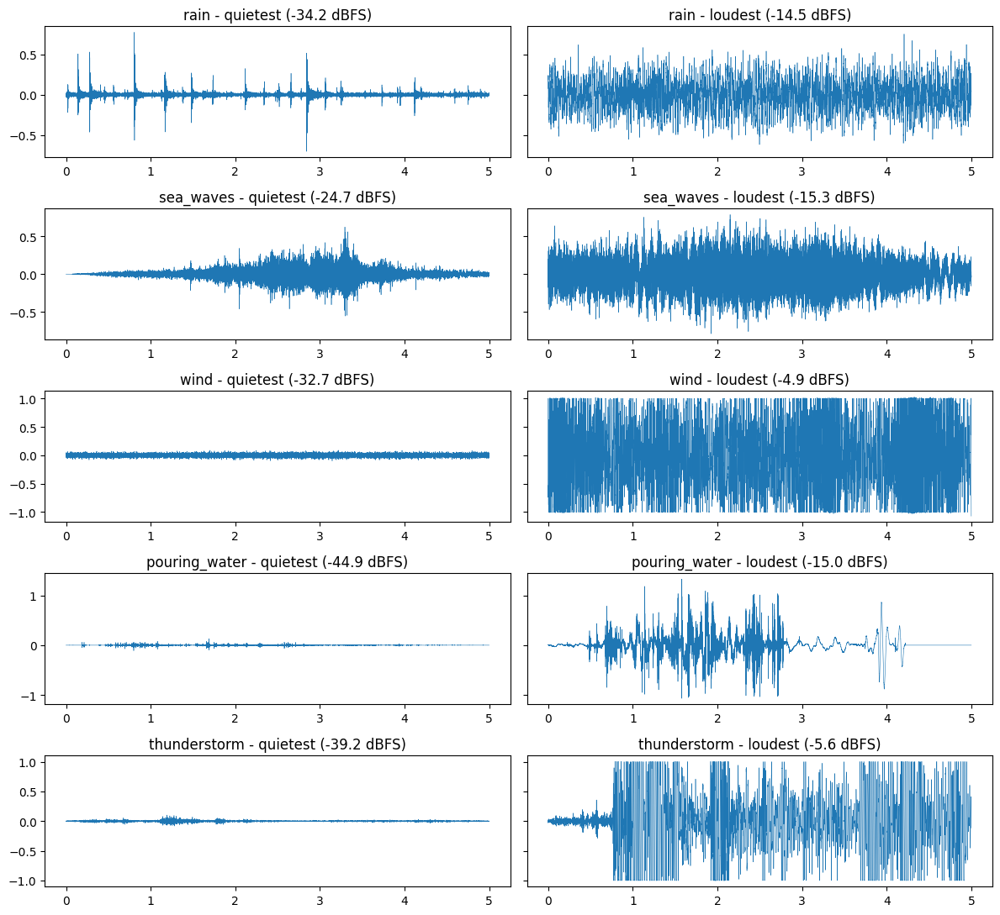

In [15]:
fig, axes = plt.subplots(len(CLASSES), 2, figsize=(12, 11), sharey="row")

for i, class_name in enumerate(CLASSES):
    part = features_with_class[features_with_class.category == class_name].sort_values("rms_dbfs")
    quietest = part.iloc[0]
    loudest = part.iloc[-1]
    for column, clip in enumerate([quietest, loudest]):
        path = meta.loc[meta.filename == clip.filename, "path"].iloc[0]
        y = read_audio(path)
        axes[i, column].plot(np.arange(len(y)) / SR, y, linewidth=0.4)
        label = "quietest" if column == 0 else "loudest"
        axes[i, column].set_title(class_name + " - " + label + " (" + str(round(clip.rms_dbfs, 1)) + " dBFS)")

plt.tight_layout()
plt.show()

In [16]:
print("Listen to the quietest and the loudest clip of each class:")
for class_name in CLASSES:
    part = features_with_class[features_with_class.category == class_name].sort_values("rms_dbfs")
    for label, clip in [("quietest", part.iloc[0]), ("loudest", part.iloc[-1])]:
        path = meta.loc[meta.filename == clip.filename, "path"].iloc[0]
        print(class_name, "-", label)
        display(Audio(filename=path))

Listen to the quietest and the loudest clip of each class:
rain - quietest


rain - loudest


sea_waves - quietest


sea_waves - loudest


wind - quietest


wind - loudest


pouring_water - quietest


pouring_water - loudest


thunderstorm - quietest


thunderstorm - loudest


The EDA shows us :


- **Size:** 200 clips, 5 classes with 40 clips each. Every class has the same split: 24 train, 8 validation, 8 test.
- **Format:** all files are 44.1 kHz, mono and exactly 5 seconds long. We resample to 16 kHz, so everything above 8 kHz is lost.
- **Padded silence:** 10 clips (9 of `pouring_water`, 1 of `sea_waves`) end with more than 0.05 s of exact zeros.
The worst one has about 3.2 s of padding, so it has only about 1.8 s of real sound. This also explains most of the high quiet ratio of `pouring_water`: padded clips have an average quiet ratio of about 0.41, the others about 0.02. Because of this we measure the features on the real sound part only.
- **Clipping:** 31 clips contain some clipped samples and 7 have more than 1%. It happens mostly in `thunderstorm` and `wind`.
- **Loudness:** `pouring_water` is the quietest class (about -33 dBFS on average, the others are around -20 to -22 dBFS). Inside one class the loudness changes a lot (`wind` goes from about -33 to -5 dBFS). That is why loudness is a usable, rough stand-in for light / heavy.
- **Brightness and sharpness:** `rain` and `pouring_water` are bright (spectral centroid around 2.7-2.8 kHz), `wind` and `thunderstorm` are dark (around 0.7-1.0 kHz). `pouring_water` has by far the spikiest clips (crest factor about 17 and dynamic range about 34 dB on average), so most of its "harsh" clips will be splashes.

In the waveform plot, the quietest `rain` clip has a few separate drops and the loudest one is dense, so the light / heavy idea looks reasonable for rain.



##5.Generation design

The diffusion model generates waveform audio conditioned on text. Each class has a comfort-oriented prompt, and a negative prompt lists what the model should stay away from (music, voices, sirens, sudden impacts and similar).


In [17]:
PROMPTS={
 'rain':'Gentle steady rain falling outside a cozy window, soft natural rain texture, relaxing continuous ambience, no music, high quality field recording',
 'sea_waves':'Small gentle ocean waves washing softly onto a quiet sandy beach, natural slow rhythmic surf, peaceful continuous ambience, no music, high quality field recording',
 'wind':'Soft warm breeze moving quietly through tree leaves, gentle rustling foliage, peaceful natural ambience, no music, high quality field recording',
 'pouring_water':'Calm continuous stream of fresh water flowing over small smooth stones, gentle babbling brook, peaceful nature ambience, no music, high quality field recording',
 'thunderstorm':'Gentle distant thunder rumbling far away beneath steady soft rain, cozy safe indoor perspective, quiet calming weather ambience, no music, high quality field recording'
}
NEGATIVE='music, speech, voice, singing, siren, alarm, explosion, gunshot, distortion, harsh noise, loud crack, abrupt impact, clipping'
assert set(PROMPTS)==set(CLASSES)
for k,v in PROMPTS.items():print(k,':',v)

rain : Gentle steady rain falling outside a cozy window, soft natural rain texture, relaxing continuous ambience, no music, high quality field recording
sea_waves : Small gentle ocean waves washing softly onto a quiet sandy beach, natural slow rhythmic surf, peaceful continuous ambience, no music, high quality field recording
wind : Soft warm breeze moving quietly through tree leaves, gentle rustling foliage, peaceful natural ambience, no music, high quality field recording
pouring_water : Calm continuous stream of fresh water flowing over small smooth stones, gentle babbling brook, peaceful nature ambience, no music, high quality field recording
thunderstorm : Gentle distant thunder rumbling far away beneath steady soft rain, cozy safe indoor perspective, quiet calming weather ambience, no music, high quality field recording


##6.Load pretrained AudioLDM 2

AudioLDM 2 is a generative deep-learning model

In [ ]:
from diffusers import AudioLDM2Pipeline
DTYPE=torch.float16 if DEVICE=='cuda' else torch.float32
pipe=AudioLDM2Pipeline.from_pretrained(MODEL_ID,revision=MODEL_REVISION,torch_dtype=DTYPE)
pipe=pipe.to(DEVICE)
if DEVICE=='cuda':
    try:pipe.enable_attention_slicing()
    except Exception:pass
MODEL_SR=int(pipe.vae.config.get('sampling_rate',16000)) if hasattr(pipe.vae.config,'get') else 16000
# The AudioLDM2 pipeline exposes the actual output sample rate via the vocoder configuration.
MODEL_SR=int(getattr(pipe.vocoder.config,'sampling_rate',MODEL_SR))
print('Loaded',MODEL_ID,'| Model output sample rate:',MODEL_SR)

# AudioLDM2Pipeline expects a GPT2LMHeadModel with generation methods,
# the checkpoint loads it as `GPT2Model`, but the pipeline needs `GPT2LMHeadModel`,
# so the cell copies the weights into the right class.
from transformers import GPT2LMHeadModel
if type(pipe.language_model).__name__ == 'GPT2Model':
    old_model = pipe.language_model
    new_model = GPT2LMHeadModel(old_model.config)
    new_model.transformer.load_state_dict(old_model.state_dict(), strict=True)
    new_model = new_model.to(
        device=next(old_model.parameters()).device,
        dtype=next(old_model.parameters()).dtype
    )
    new_model.eval()
    pipe.register_modules(language_model=new_model)
    del old_model
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
assert hasattr(pipe.language_model, '_update_model_kwargs_for_generation'), (
    'Incompatible Transformers GPT-2 generation interface'
)
print('Language model:', type(pipe.language_model).__name__)


In [ ]:
print('CUDA available:', torch.cuda.is_available())
if DEVICE == 'cuda':
    print('GPU memory GiB:', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
    torch.cuda.reset_peak_memory_stats()
inference_started = time.perf_counter()

##7.Generate candidate recordings


For each class, the cell generates 2 clips of 10 seconds from the prompt (two different random seeds), measures each clip with `audio_metrics`, and gives it a technical score.




In [ ]:
CANDIDATES_PER_CLASS=2
DURATION_SECONDS=10
INFERENCE_STEPS=50
GUIDANCE_SCALE=3.5

def make_candidate(category,seed):
    generator=torch.Generator(device=DEVICE).manual_seed(seed)
    result=pipe(prompt=PROMPTS[category],negative_prompt=NEGATIVE,
        audio_length_in_s=DURATION_SECONDS,num_inference_steps=INFERENCE_STEPS,
        guidance_scale=GUIDANCE_SCALE,generator=generator)
    y=np.asarray(result.audios[0],dtype=np.float32).reshape(-1)
    if MODEL_SR!=SR:y=librosa.resample(y,orig_sr=MODEL_SR,target_sr=SR)
    if not np.isfinite(y).all(): raise ValueError('Model returned non-finite audio')
    return y.astype(np.float32)

def quality_score(metrics):
    rms=metrics['rms']
    return float(-abs(np.log10(max(rms,1e-6))-np.log10(0.08))
        -2*metrics['quiet_ratio']-8*metrics['clipping_ratio'])

candidate_rows=[]
for index,category in enumerate(CLASSES):
    for j in range(CANDIDATES_PER_CLASS):
        seed=SEED+index*100+j
        y=make_candidate(category,seed)
        path=OUTPUT/f'{category}_candidate_{j+1}.wav'
        sf.write(path,y,SR,subtype='PCM_16')
        stats=audio_metrics(y)
        candidate_rows.append(dict(category=category,seed=seed,file=str(path),
                                   score=quality_score(stats),**stats))
        print(category,'candidate',j+1,'RMS',round(stats['rms'],4),
              'quiet',round(stats['quiet_ratio'],3))
        if DEVICE=='cuda':torch.cuda.empty_cache()
candidates=pd.DataFrame(candidate_rows)
candidates.to_csv(OUTPUT/'candidate_quality.csv',index=False)
display(candidates.sort_values(['category','score'],ascending=[True,False]))

The score prefers a loudness (RMS) near 0.08, little silence and no clipping. It cannot tell us if the clip sounds nice or like the right sound. For that, we need to listen to it.


In [ ]:
print('Generation elapsed seconds:', round(time.perf_counter() - inference_started, 1))
if DEVICE == 'cuda':
    print('Peak allocated GPU GiB:', round(torch.cuda.max_memory_allocated() / 2**30, 2))

##8.Compare candidates by ear and by spectrogram

Every class shows its candidates with a player, waveform, and spectral view.




 RAIN
rain_candidate_1.wav score -0.373


rain_candidate_2.wav score -0.625


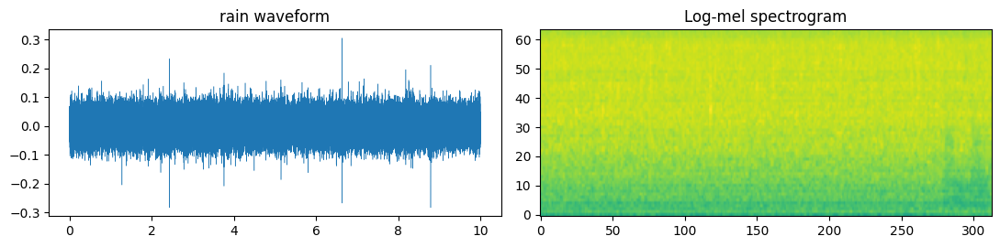


 SEA_WAVES
sea_waves_candidate_2.wav score -0.473


sea_waves_candidate_1.wav score -0.573


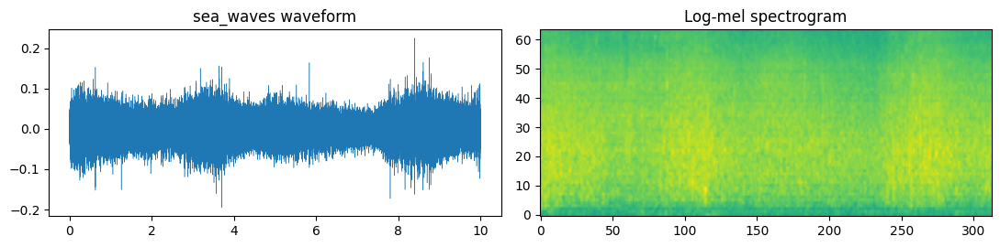


 WIND
wind_candidate_1.wav score -0.497


wind_candidate_2.wav score -0.571


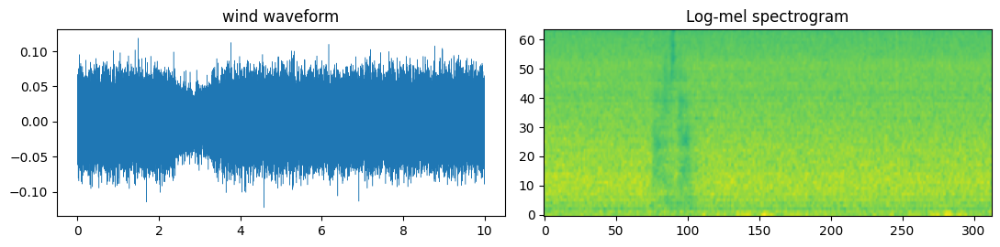


 POURING_WATER
pouring_water_candidate_2.wav score -0.26


pouring_water_candidate_1.wav score -0.413


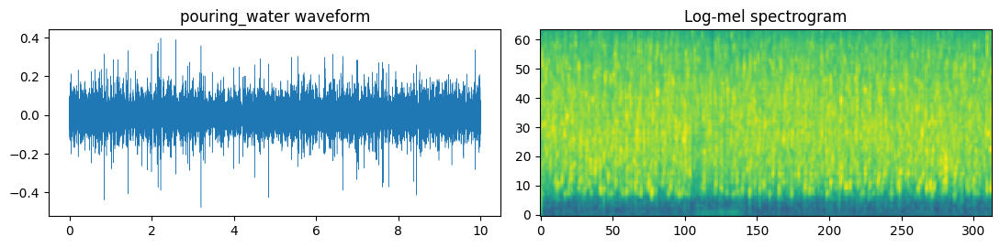


 THUNDERSTORM
thunderstorm_candidate_2.wav score -0.338


thunderstorm_candidate_1.wav score -0.848


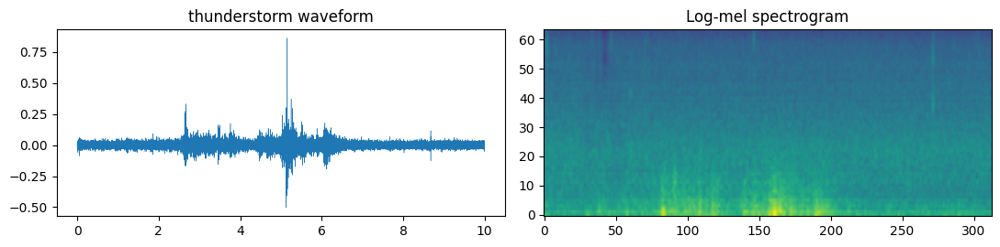

In [22]:
for category in CLASSES:
    print('\n',category.upper())
    subset=candidates[candidates.category.eq(category)].sort_values('score',ascending=False)
    fig,axes=plt.subplots(1,2,figsize=(11,2.8))
    for _,r in subset.iterrows():
        y=read_audio(r.file)
        print(Path(r.file).name,'score',round(r.score,3));display(Audio(y,rate=SR,normalize=False))
    best=read_audio(subset.iloc[0].file)
    axes[0].plot(np.arange(len(best))/SR,best,lw=.35);axes[0].set_title(category+' waveform')
    mel=librosa.feature.melspectrogram(y=best,sr=SR,n_mels=64)
    axes[1].imshow(librosa.power_to_db(mel,ref=np.max),origin='lower',aspect='auto',vmin=-80,vmax=0)
    axes[1].set_title('Log-mel spectrogram');plt.tight_layout();plt.show()

In [23]:
REVIEWED_SEEDS = {}  # Example: {'rain': 42}

##9.Gentle mastering and seamless ambient looping

The platform needs longer layers. We assemble a longer scene from each generated recording using overlapping segments and equal-power crossfades, then apply a conservative limiter and fades.



In [ ]:
def soft_master(y,target_rms=0.09,peak_limit=0.88):
    y=np.nan_to_num(np.asarray(y,dtype=np.float32))
    y=y-np.mean(y)
    rms=float(np.sqrt(np.mean(y*y)))
    if rms>1e-6:y=y*min(3.0,target_rms/rms)
    peak=float(np.max(np.abs(y))) if len(y) else 0
    if peak>peak_limit:y=y*(peak_limit/peak)
    return y.astype(np.float32)

def loop_crossfade(y,seconds=60,fade_seconds=1.0,sr=SR):
    y=np.asarray(y,dtype=np.float32)
    target=int(seconds*sr)
    if len(y)<int(2*fade_seconds*sr)+2:raise ValueError('Audio is too short for crossfade')
    overlap=int(fade_seconds*sr)
    # Create a smooth seamless single cycle by blending the original end into its start.
    # Preserve the main body while making the join continuous.
    head=y[:overlap].copy();tail=y[-overlap:].copy()
    theta=np.linspace(0,np.pi/2,overlap,endpoint=True,dtype=np.float32)
    join=tail*np.cos(theta)**2+head*np.sin(theta)**2
    cycle=np.concatenate([join,y[overlap:-overlap]])
    if len(cycle)==0:raise ValueError('Empty loop cycle')
    repeated=np.tile(cycle,int(np.ceil(target/len(cycle)))+1)[:target]
    edge=min(int(.25*sr),len(repeated)//4)
    if edge:
        repeated[:edge]*=np.linspace(0,1,edge)
        repeated[-edge:]*=np.linspace(1,0,edge)
    return repeated.astype(np.float32)

SCENE_SECONDS=60
selected=[]
for category in CLASSES:
    subset=candidates[candidates.category.eq(category)].sort_values('score',ascending=False)
    override=REVIEWED_SEEDS.get(category)
    best=subset.iloc[0] if override is None else subset[subset.seed.eq(override)].iloc[0]
    y=soft_master(read_audio(best.file))
    y=loop_crossfade(y,seconds=SCENE_SECONDS)
    path=OUTPUT/f'{category}_ambient_60s.wav'
    sf.write(path,y,SR,subtype='PCM_16')
    selected.append(dict(category=category,prompt=PROMPTS[category],seed=int(best.seed),
                         wav=path.name,source_candidate=Path(best.file).name,
                         **audio_metrics(y)))
manifest=pd.DataFrame(selected)
display(manifest)
print('Created',len(manifest),'ambient layers')

`soft_master` removes the DC offset, sets the loudness to about RMS 0.09 (it never boosts by more than 3 times) and keeps the peaks under 0.88.

`loop_crossfade` blends the end of the 10 s clip into its start and repeats it until 60 s, with a short fade in and out. So every 60 s file is the same 10 s of sound repeated smoothly, not 60 s of new sound. Because the loudness is set to the same value for every class, the final layers do not keep the loudness differences of the model output.

### Listen to the final 60-second ambient layers

These are generated 10-second recordings extended by audio mastering and looping; they are not independently generated 60-second recordings.

In [ ]:
for category in CLASSES:
    final_path = OUTPUT / f'{category}_ambient_60s.wav'
    print('Final ambient layer:', category)
    display(Audio(filename=str(final_path), normalize=False))

## 10.Platform-ready API and three-layer mixer

The exported files can be loaded by a Gradio or other application (we will use it to build the app later) without retraining or loading the diffusion model.



In [26]:
def load_layer(category):
    if category not in CLASSES:raise ValueError('Unknown category: '+str(category))
    path=OUTPUT/f'{category}_ambient_60s.wav'
    y,sr=sf.read(path,dtype='float32',always_2d=False)
    if sr!=SR:raise ValueError('Unexpected sample rate')
    return y

def mix_soundscape(levels,seconds=60):
    # Example: {'rain':20,'sea_waves':50,'wind':10}
    if any(not np.isfinite(float(v)) or float(v)<0 or float(v)>100 for v in levels.values()):
        raise ValueError('Levels must be finite and 0..100')
    active={k:float(v) for k,v in levels.items() if float(v)>0}
    if not active:raise ValueError('At least one layer must be audible')
    if any(k not in CLASSES for k in active):raise ValueError('Unknown category')
    if any(v<0 or v>100 for v in active.values()):raise ValueError('Levels must be 0..100')
    n=int(seconds*SR)
    result=np.zeros(n,dtype=np.float32)
    for category,volume in active.items():
        y=load_layer(category)
        if len(y)<n:y=np.tile(y,int(np.ceil(n/len(y))))
        result+=y[:n]*(volume/100.0)
    peak=float(np.max(np.abs(result)))
    if peak>0.9: result *= 0.9/peak
    return result

DEMO_LEVELS={'rain':60,'sea_waves':30,'wind':10}
mix=mix_soundscape(DEMO_LEVELS,seconds=60)
sf.write(OUTPUT/'demo_mix_60s.wav',mix,SR,subtype='PCM_16')
print('Mixed demo:',DEMO_LEVELS);display(Audio(mix,rate=SR,normalize=False))

Mixed demo: {'rain': 60, 'sea_waves': 30, 'wind': 10}


`load_layer` reads one 60 s layer, and `mix_soundscape` adds the layers with levels from 0 to 100 (for example rain 60, waves 30, wind 10). If the peak goes above 0.9 it lowers the volume, so the mix does not clip. The demo mix is saved as `demo_mix_60s.wav`.

##11.Interface and acceptance
Exports are mono PCM16 WAV at 16 kHz. The generated 60-second files are repeated crossfaded short clips, not novel long-form generation.


In [ ]:
def generate_nature_audio(category, duration_seconds, seed=None):
    """Run pretrained inference and return a mono float32 waveform and metadata."""
    if category not in PROMPTS:
        raise ValueError('Unknown category')
    if not 1 <= duration_seconds <= 10:
        raise ValueError('Generate 1 to 10 seconds per call; use the loop workflow for longer audio')
    seed = SEED if seed is None else int(seed)
    result = pipe(prompt=PROMPTS[category], negative_prompt=NEGATIVE,
                  audio_length_in_s=float(duration_seconds), num_inference_steps=INFERENCE_STEPS,
                  guidance_scale=GUIDANCE_SCALE, generator=torch.Generator(device=DEVICE).manual_seed(seed))
    audio = np.asarray(result.audios[0], dtype=np.float32).reshape(-1)
    if not np.isfinite(audio).all() or not len(audio):
        raise ValueError('Invalid model output')
    if MODEL_SR != SR:
        audio = librosa.resample(audio, orig_sr=MODEL_SR, target_sr=SR)
    return audio, {'category': category, 'seed': seed, 'sample_rate': SR,
                   'model': MODEL_ID, 'revision': MODEL_REVISION, 'prompt': PROMPTS[category],
                   'negative_prompt': NEGATIVE, 'steps': INFERENCE_STEPS, 'guidance': GUIDANCE_SCALE}

# Deterministic signal-processing checks; synthetic signals are test fixtures only.
test_t = np.arange(SR * 3) / SR
test_signal = (0.1 * np.sin(2 * np.pi * 220 * test_t)).astype(np.float32)
assert abs(audio_metrics(test_signal)['rms'] - 0.07071) < 0.001
test_loop = loop_crossfade(test_signal, seconds=5, fade_seconds=0.25)
assert len(test_loop) == 5 * SR and np.isfinite(test_loop).all()
assert abs(float(test_loop[0] - test_loop[-1])) < 1e-6
assert np.max(np.abs(soft_master(test_signal))) <= 0.881
print('Signal-processing tests passed')

##11.Automated export validation



In [ ]:
checks=[]
for row in selected:
    path=OUTPUT/row['wav']
    y,sr=sf.read(path,dtype='float32')
    stats=audio_metrics(y,sr)
    ok=(sr==SR and abs(stats['duration_s']-SCENE_SECONDS)<0.02 and
        np.isfinite(y).all() and stats['peak']<=0.92 and stats['rms']>0.001)
    checks.append(dict(category=row['category'],passed=bool(ok),**stats))
report=pd.DataFrame(checks)
display(report)
assert report.passed.all(),'Export validation failed; inspect report before deployment.'
package={'project':'SoundScape AI','version':'1.0','audio_format':'mono PCM16 WAV',
         'sample_rate':SR,'duration_seconds':SCENE_SECONDS,'generator':MODEL_ID,
         'inference_steps':INFERENCE_STEPS, 'guidance_scale':GUIDANCE_SCALE,
         'negative_prompt':NEGATIVE, 'model_revision':MODEL_REVISION, 'model_license':'CC-BY-NC-SA-4.0',
         'selection':'technical screening with optional human override',
         'listening_review':'not recorded',
         'quality_note':'Technical checks passed; listening review is still required.',
         'classes':selected,'demo_mix':'demo_mix_60s.wav'}
with open(OUTPUT/'manifest.json','w') as f:json.dump(package,f,indent=2)
report.to_csv(OUTPUT/'export_validation.csv',index=False)
import zipfile
with zipfile.ZipFile('soundscape_nature_platform_export.zip','w',zipfile.ZIP_DEFLATED) as z:
    for path in OUTPUT.glob('*'):
        if path.name.endswith(('_ambient_60s.wav','.json','.csv')) or path.name=='demo_mix_60s.wav':
            z.write(path,arcname=path.name)
print('READY: soundscape_nature_platform_export.zip')

this cell checks every exported 60 s file (sample rate, length, finite numbers, peak not above 0.92, not silent), writes `manifest.json` and makes a zip with the layers and the reports.


### Exporting the generated files

All WAVs and metadata are stored in `soundscape_export/`.

In [29]:
# Optional: run this cell manually in Google Colab to download the export archive.
# from google.colab import files
# files.download('soundscape_nature_platform_export.zip')

##12.Fine-tuning: controllable and comfort-oriented generation

1. **Controllable generation:** the user asks for a *light*, *moderate* or *heavy* sound (light rain instead of just rain).
2. **Comfort-oriented generation:** the user asks for a *calm and soft* sound and the model stays away from *harsh and sudden* ones (distant soft thunder instead of loud thunder).

**Method: LoRA fine-tuning.** AudioLDM 2 stays frozen. we only train small extra matrices inside its cross-attention layers, which is where the text prompt talks to the audio.

**Main problem:** the data has no captions or labels. ESC-50 has no text description, no intensity label and no comfort label, so we create them from the audio:

- **Intensity:** inside each class, the quietest third of the clips is "light", the middle third is "moderate" and the loudest third is "heavy" (by RMS loudness).
- **Comfort:** a harshness score from brightness, crest factor and dynamic range (the numbers from the EDA). The calmer half of each class is "calm", the other half is "harsh".





###12.1 Baseline check: do the generated clips match the real recordings in loudness?

Before fine-tuning, we compare the loudness of the generated clips (the `candidates` table) with the real ESC-50 clips.
Real classes differ a lot in loudness, while the generated clips are probably all at a similar level


,real_mean_dbfs,generated_mean_dbfs,difference
category,,,
rain,-22.4,-31.9,-9.5
sea_waves,-20.0,-32.4,-12.4
wind,-19.5,-32.6,-13.1
pouring_water,-33.2,-28.7,4.5
thunderstorm,-21.6,-33.8,-12.2


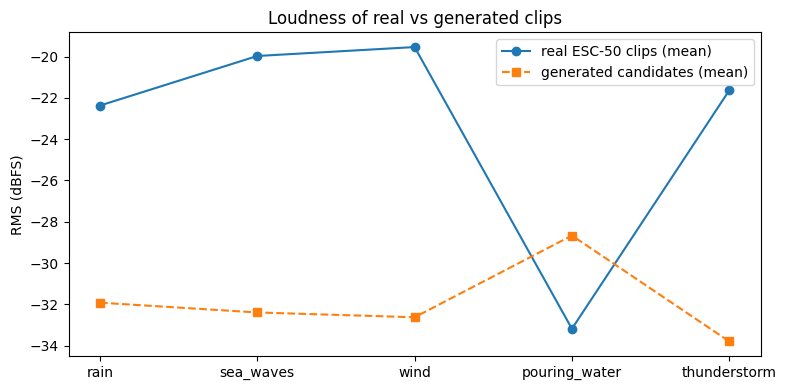

In [30]:
generated_loudness = candidates.groupby("category")["rms_dbfs"].mean()
real_loudness = audit.groupby("category")["rms_dbfs"].mean()

loudness_comparison = pd.DataFrame({"real_mean_dbfs": real_loudness,
                                    "generated_mean_dbfs": generated_loudness}).loc[CLASSES]
loudness_comparison["difference"] = loudness_comparison.generated_mean_dbfs - loudness_comparison.real_mean_dbfs
display(loudness_comparison.round(1))

positions = np.arange(len(CLASSES))
plt.figure(figsize=(8, 4))
plt.plot(positions, loudness_comparison.real_mean_dbfs, "o-", label="real ESC-50 clips (mean)")
plt.plot(positions, loudness_comparison.generated_mean_dbfs, "s--", label="generated candidates (mean)")
plt.xticks(positions, CLASSES)
plt.ylabel("RMS (dBFS)")
plt.title("Loudness of real vs generated clips")
plt.legend()
plt.tight_layout()
plt.show()

###12.2 Build captions, intensity labels and comfort labels




In [ ]:
ft = meta.merge(features[["filename", "rms_dbfs", "crest_factor", "centroid_hz", "dynamic_range_db"]], on="filename")

# RMS of the clip after peak normalization (peak = 0.5). It equals 0.5 / crest factor, so it tells how dense
# and continuous a sound is, no matter how loud it was recorded.
ft["norm_rms_dbfs"] = 20 * np.log10(0.5 / ft["crest_factor"])

# Intensity label: split every class into 3 equal groups by loudness
ft["intensity"] = ""
for class_name in CLASSES:
    in_class = ft.category == class_name
    loudness_rank = ft.loc[in_class, "rms_dbfs"].rank(method="first")
    ft.loc[in_class, "intensity"] = pd.qcut(loudness_rank, q=3, labels=["light", "medium", "heavy"]).astype(str)

# Comfort label: harshness score = average rank (inside the class) of brightness, crest factor and dynamic range
rank_columns = []
for column in ["centroid_hz", "crest_factor", "dynamic_range_db"]:
    rank_columns.append(ft.groupby("category")[column].rank(pct=True))
ft["harsh_score"] = pd.concat(rank_columns, axis=1).mean(axis=1)

ft["comfort"] = "calm"
for class_name in CLASSES:
    in_class = ft.category == class_name
    middle = ft.loc[in_class, "harsh_score"].median()
    ft.loc[in_class & (ft.harsh_score > middle), "comfort"] = "harsh"

# Words used in the captions
CLASS_WORDS = {"rain": "rain", "sea_waves": "ocean waves", "wind": "wind",
               "pouring_water": "flowing water", "thunderstorm": "thunderstorm"}
INTENSITY_WORDS = {"light": "light and gentle", "medium": "moderate", "heavy": "heavy and strong"}
COMFORT_WORDS = {"calm": "calm and soft", "harsh": "harsh and sudden"}

ft["caption_intensity"] = [INTENSITY_WORDS[i] + " " + CLASS_WORDS[c] for i, c in zip(ft.intensity, ft.category)]
ft["caption_comfort"] = [COMFORT_WORDS[k] + " " + CLASS_WORDS[c] for k, c in zip(ft.comfort, ft.category)]
ft["caption_joint"] = [COMFORT_WORDS[k] + ", " + INTENSITY_WORDS[i] + " " + CLASS_WORDS[c]
                       for k, i, c in zip(ft.comfort, ft.intensity, ft.category)]

# One adapter per idea; each adapter is trained with its own caption column
ADAPTER_CAPTIONS = {"intensity": "caption_intensity", "comfort": "caption_comfort", "joint": "caption_joint"}

ft.to_csv(EXTRA / "finetune_labels.csv", index=False)

print("Training clips per label:")
train_part = ft[ft.split == "train"]
display(pd.crosstab(train_part.category, train_part.intensity))
display(pd.crosstab(train_part.category, train_part.comfort))

print("What the labels mean in numbers (mean over all clips):")
display(ft.groupby("intensity")["rms_dbfs"].mean().loc[["light", "medium", "heavy"]].round(1))
display(ft.groupby("comfort")[["centroid_hz", "crest_factor", "dynamic_range_db"]].mean().round(1))

print("Example captions:")
display(ft[["filename", "intensity", "comfort", "caption_intensity", "caption_comfort", "caption_joint"]].sample(6, random_state=SEED))

###12.3 Check that the audio can go into the model

AudioLDM 2 does not work on waveforms directly. A VAE encoder turns a **log-mel spectrogram** into a small latent image, the U-Net learns to denoise that latent, and a vocoder turns the mel spectrogram back into sound. To fine-tune, we have to make the same kind of mel spectrogram from the ESC-50 clips.


16 kHz audio, first remove the DC offset and set the peak to 0.5, then a magnitude STFT (window 1024, hop 160, reflect padding), 64 mel bins from 0 to 8000 Hz, and the natural log with a floor of 1e-5.

we use a crop of 480 frames (4.8 seconds) from each 5-second clip. The crop length has to be divisible by 8 for the U-Net.

In [ ]:
MEL_BINS = 64
MEL_HOP = 160
MEL_FFT = 1024
CROP_FRAMES = 480
MEL_FILTERS = librosa.filters.mel(sr=SR, n_fft=MEL_FFT, n_mels=MEL_BINS, fmin=0, fmax=8000)

def peak_normalize(y, peak=0.5):
    # Same as normalize_wav in the AudioLDM 2 code: remove the DC offset, then set the highest peak to 0.5
    y = y - np.mean(y)
    return (y / (np.max(np.abs(y)) + 1e-8) * peak).astype(np.float32)

def clip_to_log_mel(y):
    # Same as the AudioLDM 2 code: normalize -> magnitude STFT (reflect padding) -> 64 mel bins -> natural log
    y = peak_normalize(y)
    stft = librosa.stft(y, n_fft=MEL_FFT, hop_length=MEL_HOP, win_length=MEL_FFT,
                        window="hann", center=True, pad_mode="reflect")
    mel = MEL_FILTERS @ np.abs(stft)
    return np.log(np.clip(mel, 1e-5, None)).T.astype(np.float32)   # shape: (time frames, 64)

mel_cache = {}

def get_log_mel(path):
    if path not in mel_cache:
        mel_cache[path] = clip_to_log_mel(read_audio(path))
    return mel_cache[path]

example_mel = get_log_mel(ft.path.iloc[0])
print("Log-mel shape of one 5 s clip (frames, mel bins):", example_mel.shape)
print("Value range:", round(float(example_mel.min()), 2), "to", round(float(example_mel.max()), 2))
assert example_mel.shape[1] == MEL_BINS and example_mel.shape[0] >= CROP_FRAMES

In [33]:
vocoder_config = pipe.vocoder.config
print("Vocoder input bins:", getattr(vocoder_config, "model_in_dim", "unknown"))
print("Vocoder sample rate:", getattr(vocoder_config, "sampling_rate", "unknown"))
print("Vocoder upsample rates:", getattr(vocoder_config, "upsample_rates", "unknown"), "(product should be 160 = MEL_HOP)")
print("VAE scaling factor:", pipe.vae.config.scaling_factor)

# Take one real rain clip and send it through the same path the model will use
test_path = ft.loc[ft.category == "rain", "path"].iloc[0]
test_audio = peak_normalize(read_audio(test_path))
test_mel = get_log_mel(test_path)[:CROP_FRAMES]
mel_tensor = torch.from_numpy(np.ascontiguousarray(test_mel)).to(DEVICE, DTYPE)[None, None]   # (1, 1, time, 64)

with torch.no_grad():
    latents = pipe.vae.encode(mel_tensor).latent_dist.mode()
    rebuilt_mel = pipe.vae.decode(latents).sample
    wave_from_mel = pipe.vocoder(mel_tensor.squeeze(1))
    wave_from_vae = pipe.vocoder(rebuilt_mel.squeeze(1))

print("mel tensor:", tuple(mel_tensor.shape), "| latent:", tuple(latents.shape), "| rebuilt mel:", tuple(rebuilt_mel.shape))
correlation = np.corrcoef(test_mel.ravel(), rebuilt_mel.float().cpu().numpy().ravel())[0, 1]
print("Correlation between the original mel and the VAE-rebuilt mel:", round(float(correlation), 3))

print("1) original clip (normalized the same way)")
display(Audio(test_audio, rate=SR, normalize=False))
print("2) my mel -> vocoder (tests the mel recipe)")
display(Audio(wave_from_mel.squeeze().float().cpu().numpy(), rate=SR, normalize=False))
print("3) my mel -> VAE -> vocoder (tests the VAE path)")
display(Audio(wave_from_vae.squeeze().float().cpu().numpy(), rate=SR, normalize=False))

Vocoder input bins: 64
Vocoder sample rate: 16000
Vocoder upsample rates: [5, 4, 2, 2, 2] (product should be 160 = MEL_HOP)
VAE scaling factor: 0.4110932946205139
mel tensor: (1, 1, 480, 64) | latent: (1, 8, 120, 16) | rebuilt mel: (1, 1, 480, 64)
Correlation between the original mel and the VAE-rebuilt mel: 0.992
1) original clip (normalized the same way)


2) my mel -> vocoder (tests the mel recipe)


3) my mel -> VAE -> vocoder (tests the VAE path)


###12.4 Add LoRA to the U-Net

LoRA leaves every original weight untouched. For each chosen linear layer it adds a small trainable correction `B @ A` (rank 8). At the start `B` is all zeros, so the model gives exactly the same output as before. Only `A` and `B` are trained, which is a tiny part of the model.

we add LoRA to the cross-attention layers (`attn2`). To also adapt the self-attention layers, add `"attn1"` to `LORA_PARTS` (more capacity, but a higher risk of overfitting on 120 clips).

In [34]:
import math
from torch import nn
from torch.nn import functional as F

class LoRALinear(nn.Module):
    # A frozen Linear layer plus a small trainable low-rank correction
    def __init__(self, base_layer, rank=8, alpha=8):
        super().__init__()
        self.base = base_layer
        self.scale = alpha / rank
        self.enabled = True
        device = base_layer.weight.device
        self.lora_A = nn.Parameter(torch.zeros(rank, base_layer.in_features, device=device, dtype=torch.float32))
        self.lora_B = nn.Parameter(torch.zeros(base_layer.out_features, rank, device=device, dtype=torch.float32))
        self.reset()

    def reset(self):
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        nn.init.zeros_(self.lora_B)

    # The attention code may look at these attributes of the original layer
    @property
    def weight(self):
        return self.base.weight

    @property
    def bias(self):
        return self.base.bias

    @property
    def in_features(self):
        return self.base.in_features

    @property
    def out_features(self):
        return self.base.out_features

    def forward(self, x):
        output = self.base(x)
        if not self.enabled:
            return output
        correction = (x.to(torch.float32) @ self.lora_A.t()) @ self.lora_B.t()
        return output + (correction * self.scale).to(output.dtype)

In [ ]:
LORA_RANK = 8
LORA_PARTS = ("attn2",)
LORA_LAYERS = ("to_q", "to_k", "to_v", "to_out.0")

lora_modules = {}      # name of the layer -> its LoRALinear wrapper
adapter_states = {}    # name of a trained adapter -> saved LoRA weights

def add_lora_to_unet(unet):
    unet.requires_grad_(False)          # freeze the whole original U-Net
    target_names = []
    for name, module in unet.named_modules():
        in_chosen_part = any(part in name.split(".") for part in LORA_PARTS)
        if isinstance(module, nn.Linear) and in_chosen_part and name.endswith(LORA_LAYERS):
            target_names.append(name)
    for name in target_names:
        parent_name, child_name = name.rsplit(".", 1)
        parent = unet.get_submodule(parent_name)
        wrapped = LoRALinear(getattr(parent, child_name), rank=LORA_RANK, alpha=LORA_RANK)
        setattr(parent, child_name, wrapped)
        lora_modules[name] = wrapped
    return len(target_names)

def lora_parameters():
    parameters = []
    for module in lora_modules.values():
        parameters.append(module.lora_A)
        parameters.append(module.lora_B)
    return parameters

def set_lora_enabled(flag):
    for module in lora_modules.values():
        module.enabled = flag

def reset_lora():
    for module in lora_modules.values():
        module.reset()

def get_lora_state():
    state = {}
    for name, module in lora_modules.items():
        state[name] = (module.lora_A.detach().cpu().clone(), module.lora_B.detach().cpu().clone())
    return state

def load_lora_state(state):
    with torch.no_grad():
        for name, (matrix_a, matrix_b) in state.items():
            lora_modules[name].lora_A.copy_(matrix_a)
            lora_modules[name].lora_B.copy_(matrix_b)

def use_adapter(name):
    if name is None:
        set_lora_enabled(False)
    else:
        load_lora_state(adapter_states[name])
        set_lora_enabled(True)

if len(lora_modules) == 0:
    layer_count = add_lora_to_unet(pipe.unet)
else:
    layer_count = len(lora_modules)

trainable_count = sum(p.numel() for p in lora_parameters())
total_count = sum(p.numel() for p in pipe.unet.parameters())
print("Layers with LoRA:", layer_count)
print("Trainable LoRA parameters:", trainable_count, "out of", total_count, "in the U-Net")
assert layer_count > 0, "No attention layers were found. Print pipe.unet.named_modules() and check the names."

###12.5 Get the text conditioning from the pipeline itself

AudioLDM 2 gives the U-Net two kinds of text information (from the CLAP/T5 encoders and from GPT-2). Instead of rebuilding that by hand, we run the pipeline for one tiny step and copy exactly the tensors it passes to the U-Net.

In [ ]:
pipe.set_progress_bar_config(disable=True)
cond_cache = {}

def get_conditioning(caption):
    # Text inputs that the pipeline gives to the U-Net for this caption
    if caption in cond_cache:
        return cond_cache[caption]
    captured = {}

    def grab_inputs(module, args, kwargs):
        if len(captured) == 0:
            for key, value in kwargs.items():
                if torch.is_tensor(value) and key not in ("sample", "timestep"):
                    captured[key] = value.detach().clone()

    handle = pipe.unet.register_forward_pre_hook(grab_inputs, with_kwargs=True)
    try:
        pipe(prompt=caption, num_inference_steps=1, guidance_scale=1.0, audio_length_in_s=2.56)
    finally:
        handle.remove()

    assert len(captured) > 0, "Could not copy the U-Net inputs from the pipeline."
    cond_cache[caption] = captured
    return captured

check_caption = "light and gentle rain"
check_cond = get_conditioning(check_caption)
print("Tensors that the pipeline gives to the U-Net:")
for key, value in check_cond.items():
    print("  ", key, tuple(value.shape), value.dtype)

CAPTION_DROPOUT = 0.1
try:
    get_conditioning("")
except Exception as error:
    CAPTION_DROPOUT = 0.0
    print("Empty caption is not supported here, caption dropout is switched off:", error)

# Safety check: right after adding LoRA (B = 0) the model must give the same output with LoRA on or off
latent_channels = pipe.unet.config.in_channels
test_latents = torch.randn(1, latent_channels, CROP_FRAMES // 4, MEL_BINS // 4, device=DEVICE, dtype=DTYPE)
test_timestep = torch.tensor([500], device=DEVICE)
with torch.no_grad():
    set_lora_enabled(False)
    output_off = pipe.unet(test_latents, test_timestep, **check_cond, return_dict=False)[0]
    set_lora_enabled(True)
    output_on = pipe.unet(test_latents, test_timestep, **check_cond, return_dict=False)[0]
set_lora_enabled(False)
print("U-Net output shape:", tuple(output_on.shape))
print("Largest difference between LoRA on and off (should be 0):", float((output_on - output_off).abs().max()))

###13.Training code

The training goal is the normal diffusion one:

1. Turn a clip into a latent (VAE encoder, random 4.8 s crop).
2. Add random noise to it at a random noise level.
3. Ask the U-Net to predict the noise, given the caption of that clip.
4. Compare with the real noise (MSE loss) and update **only the LoRA weights**.

we take one clip per forward pass and add the gradients of 4 clips before each update (gradient accumulation), because captions have different lengths and this keeps memory low on a T4. The validation loss uses fixed noise and fixed noise levels, so it can be compared between steps.

In [37]:
from diffusers import DDPMScheduler

train_scheduler = DDPMScheduler.from_config(pipe.scheduler.config)
print("Noise schedule:", type(train_scheduler).__name__, "| prediction type:", train_scheduler.config.prediction_type)

def encode_clip(path, random_crop):
    mel = get_log_mel(path)
    if random_crop:
        start = random.randint(0, mel.shape[0] - CROP_FRAMES)
    else:
        start = (mel.shape[0] - CROP_FRAMES) // 2
    piece = np.ascontiguousarray(mel[start:start + CROP_FRAMES])
    tensor = torch.from_numpy(piece).to(DEVICE, DTYPE)[None, None]
    with torch.no_grad():
        distribution = pipe.vae.encode(tensor).latent_dist
        latents = distribution.sample() if random_crop else distribution.mode()
    return latents * pipe.vae.config.scaling_factor

def diffusion_loss(latents, cond, timestep, noise):
    noisy_latents = train_scheduler.add_noise(latents.float(), noise, timestep).to(latents.dtype)
    prediction = pipe.unet(noisy_latents, timestep, **cond, return_dict=False)[0]
    if train_scheduler.config.prediction_type == "v_prediction":
        target = train_scheduler.get_velocity(latents.float(), noise, timestep)
    else:
        target = noise
    return F.mse_loss(prediction.float(), target.float())

def validation_loss(caption_column, split="validation", timesteps=(200, 500, 800)):
    # Same clips, same noise, same noise levels every time, so the numbers can be compared
    rows = ft[ft.split == split]
    generator = torch.Generator(device=DEVICE).manual_seed(123)
    losses = []
    pipe.unet.eval()
    with torch.no_grad():
        for row in rows.itertuples():
            cond = get_conditioning(getattr(row, caption_column))
            latents = encode_clip(row.path, random_crop=False)
            for level in timesteps:
                noise = torch.randn(latents.shape, generator=generator, device=DEVICE, dtype=torch.float32)
                timestep = torch.tensor([level], device=DEVICE).long()
                losses.append(diffusion_loss(latents, cond, timestep, noise).item())
    return float(np.mean(losses))

Noise schedule: DDPMScheduler | prediction type: epsilon


In [38]:
def train_adapter(caption_column, steps, learning_rate=1e-4, accumulation=4, check_every=25):
    torch.manual_seed(SEED)
    random.seed(SEED)
    reset_lora()
    set_lora_enabled(True)
    parameters = lora_parameters()
    optimizer = torch.optim.AdamW(parameters, lr=learning_rate, weight_decay=0.0)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))
    train_rows = ft[ft.split == "train"].reset_index(drop=True)

    for caption in list(ft[caption_column].unique()) + [""]:
        if caption != "" or CAPTION_DROPOUT > 0:
            get_conditioning(caption)

    history = dict(train_loss=[], val_step=[0], val_loss=[validation_loss(caption_column)])
    print("step    0 | validation loss", round(history["val_loss"][0], 4), "(before training)")

    started = time.perf_counter()
    for step in range(1, steps + 1):
        pipe.unet.train()
        optimizer.zero_grad(set_to_none=True)
        step_loss = 0.0
        for _ in range(accumulation):
            row = train_rows.iloc[random.randrange(len(train_rows))]
            caption = row[caption_column]
            if random.random() < CAPTION_DROPOUT:
                caption = ""
            cond = get_conditioning(caption)
            latents = encode_clip(row.path, random_crop=True)
            noise = torch.randn_like(latents, dtype=torch.float32)
            timestep = torch.randint(0, train_scheduler.config.num_train_timesteps, (1,), device=DEVICE).long()
            loss = diffusion_loss(latents, cond, timestep, noise) / accumulation
            scaler.scale(loss).backward()
            step_loss += loss.item()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(parameters, 1.0)
        scaler.step(optimizer)
        scaler.update()
        history["train_loss"].append(step_loss)

        if step % check_every == 0 or step == steps:
            val = validation_loss(caption_column)
            history["val_step"].append(step)
            history["val_loss"].append(val)
            minutes = (time.perf_counter() - started) / 60
            print("step", str(step).rjust(4), "| train loss", round(float(np.mean(history["train_loss"][-check_every:])), 4),
                  "| validation loss", round(val, 4), "|", round(minutes, 1), "min")

    pipe.unet.eval()
    set_lora_enabled(False)
    return history

###14.Train the adapters

Two adapters, one for each idea:

- `intensity`: captions like *"heavy and strong rain"*
- `comfort`: captions like *"calm and soft rain"* and *"harsh and sudden rain"*



In [ ]:
ADAPTERS_TO_TRAIN = ["intensity", "comfort"]
TRAIN_STEPS = 150

if DEVICE == "cuda":
    gc.collect()
    torch.cuda.empty_cache()

histories = {}
for adapter_name in ADAPTERS_TO_TRAIN:
    column = ADAPTER_CAPTIONS[adapter_name]
    print("=" * 70)
    print("Training adapter:", adapter_name, "| example caption:", ft[column].iloc[0])
    histories[adapter_name] = train_adapter(column, steps=TRAIN_STEPS)
    adapter_states[adapter_name] = get_lora_state()

use_adapter(None)
print("Done. Trained adapters:", list(adapter_states))

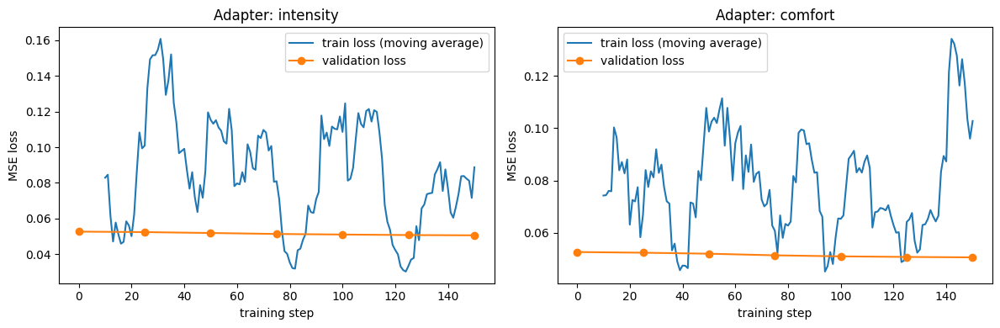

intensity | validation loss before: 0.0526 after: 0.0506 | change: -3.9 %
comfort | validation loss before: 0.0526 after: 0.0506 | change: -3.9 %


In [40]:
fig, axes = plt.subplots(1, len(histories), figsize=(6 * len(histories), 4), squeeze=False)

for axis, (adapter_name, history) in zip(axes[0], histories.items()):
    train_loss = np.array(history["train_loss"])
    window = min(10, len(train_loss))
    smooth = np.convolve(train_loss, np.ones(window) / window, mode="valid")
    axis.plot(range(window, len(train_loss) + 1), smooth, label="train loss (moving average)")
    axis.plot(history["val_step"], history["val_loss"], "o-", label="validation loss")
    axis.set_title("Adapter: " + adapter_name)
    axis.set_xlabel("training step")
    axis.set_ylabel("MSE loss")
    axis.legend()

plt.tight_layout()
plt.show()

for adapter_name, history in histories.items():
    before = history["val_loss"][0]
    after = history["val_loss"][-1]
    print(adapter_name, "| validation loss before:", round(before, 4), "after:", round(after, 4),
          "| change:", round(100 * (after - before) / before, 1), "%")

Validation loss is measured on fold 4 clips that were never used for training.


In [ ]:
# The test fold (fold 5) is used only here, once, after training is finished
test_rows = []
for adapter_name in adapter_states:
    column = ADAPTER_CAPTIONS[adapter_name]
    use_adapter(None)
    original_loss = validation_loss(column, split="test")
    use_adapter(adapter_name)
    tuned_loss = validation_loss(column, split="test")
    test_rows.append(dict(adapter=adapter_name, original_model_loss=original_loss, fine_tuned_loss=tuned_loss,
                          change_percent=100 * (tuned_loss - original_loss) / original_loss))
use_adapter(None)
display(pd.DataFrame(test_rows).round(4))

#### Training results

- All the checks before training passed: the mel recipe gives 501 frames x 64 bins for a 5 s clip, the VAE rebuilds the mel with a correlation of 0.992, LoRA was added to 192 attention layers (1,585,152 trainable parameters, about 0.45% of the 348.5 million U-Net parameters), and the U-Net output was identical with LoRA on or off before training (difference 0.0).
- Each adapter took about 8 minutes on the T4 for 150 steps (7.8 min for intensity, 7.7 min for comfort).
- Validation loss (fold 4) went from 0.0526 to 0.0506 for both adapters (-3.9%). On the test fold (fold 5) the loss went from 0.0552 to 0.0526 for intensity (-4.5%) and from 0.0548 to 0.0527 for comfort (-4.0%).
- The train loss is very noisy (about 0.03 to 0.16) because every step uses random noise levels, so only the validation curve is useful.

**What it means.** The small and steady drop in validation and test loss shows that the LoRA training works and does not overfit in 150 steps. But the two adapters are almost identical (nearly the same validation loss at every check) even though they used different captions. This suggests that most of the gain is the model adapting to the ESC-50 sounds in general, and not learning what "light", "heavy", "calm" or "harsh" mean. This is our interpretation and we did not test it. A lower loss alone does not prove better control, so the generation tests below decide.

##15.generation tests

Here we use the model to make sounds. `generate_text` makes one clip from any text and can switch between the original model and a fine-tuned adapter.

In [42]:
def generate_text(prompt, adapter=None, seed=SEED, duration=DURATION_SECONDS, negative_prompt=NEGATIVE):
    use_adapter(adapter)
    try:
        generator = torch.Generator(device=DEVICE).manual_seed(seed)
        result = pipe(prompt=prompt, negative_prompt=negative_prompt, audio_length_in_s=float(duration),
                      num_inference_steps=INFERENCE_STEPS, guidance_scale=GUIDANCE_SCALE, generator=generator)
    finally:
        use_adapter(None)
    audio = np.asarray(result.audios[0], dtype=np.float32).reshape(-1)
    if MODEL_SR != SR:
        audio = librosa.resample(audio, orig_sr=MODEL_SR, target_sr=SR)
    if not np.isfinite(audio).all():
        raise ValueError("Model returned non-finite audio")
    return audio

def harshness_vs_real(class_name, features_of_clip):
    # 0 = calmer than every real clip of the class, 1 = harsher than every real clip of the class
    real = ft[ft.category == class_name]
    parts = []
    for column in ["centroid_hz", "crest_factor", "dynamic_range_db"]:
        parts.append(float((real[column] < features_of_clip[column]).mean()))
    return sum(parts) / len(parts)

#### Test A: controllable intensity (light / moderate / heavy)

Same prompts, same random seed, only the intensity word changes.

Every generated clip is first normalized to peak 0.5 (like the training audio), then I measure its RMS.



In [ ]:
EVAL_SEEDS = [42]
LEVELS = ["light", "medium", "heavy"]

intensity_models = [None]
if "intensity" in adapter_states:
    intensity_models.append("intensity")

intensity_rows = []
for class_name in CLASSES:
    for level in LEVELS:
        prompt = INTENSITY_WORDS[level] + " " + CLASS_WORDS[class_name]
        for model_name in intensity_models:
            for seed in EVAL_SEEDS:
                audio = generate_text(prompt, adapter=model_name, seed=seed)
                level_value = audio_metrics(peak_normalize(audio))["rms_dbfs"]
                intensity_rows.append(dict(category=class_name, level=level, model=model_name or "original",
                                           seed=seed, norm_rms_dbfs=level_value))
        print(class_name, level, "done")

intensity_results = pd.DataFrame(intensity_rows)
intensity_results.to_csv(EXTRA / "test_intensity.csv", index=False)
display(intensity_results.pivot_table(index=["category", "model"], columns="level", values="norm_rms_dbfs").loc[:, LEVELS].round(1))

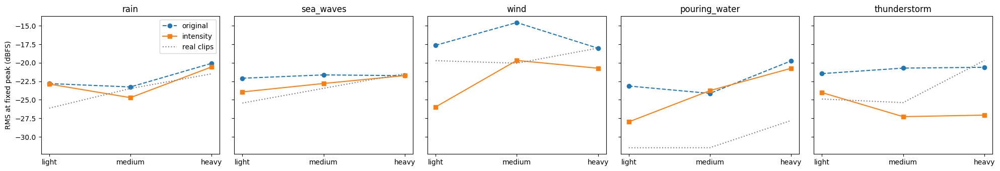

,model,category,generated_change_db,real_change_db,same_direction
0,original,rain,2.7,4.6,True
1,original,sea_waves,0.3,4.0,True
2,original,wind,-0.4,1.7,False
3,original,pouring_water,3.4,3.7,True
4,original,thunderstorm,0.9,5.2,True
5,intensity,rain,2.3,4.6,True
6,intensity,sea_waves,2.2,4.0,True
7,intensity,wind,5.2,1.7,True
8,intensity,pouring_water,7.2,3.7,True
9,intensity,thunderstorm,-3.0,5.2,False


Classes (out of 5 ) where heavy-minus-light has the same direction as in the real clips:
model
intensity    4
original     4
Name: same_direction, dtype: int64


In [44]:
real_levels = ft.groupby(["category", "intensity"])["norm_rms_dbfs"].mean()

fig, axes = plt.subplots(1, len(CLASSES), figsize=(4 * len(CLASSES), 3.5), sharey=True)
for axis, class_name in zip(axes, CLASSES):
    for model_name, style in [("original", "o--"), ("intensity", "s-")]:
        part = intensity_results[(intensity_results.category == class_name) & (intensity_results.model == model_name)]
        if len(part) > 0:
            means = part.groupby("level")["norm_rms_dbfs"].mean().loc[LEVELS]
            axis.plot(LEVELS, means.values, style, label=model_name)
    axis.plot(LEVELS, [real_levels[(class_name, level)] for level in LEVELS], ":", color="gray", label="real clips")
    axis.set_title(class_name)
axes[0].set_ylabel("RMS at fixed peak (dBFS)")
axes[0].legend()
plt.tight_layout()
plt.show()

# Does "heavy minus light" go in the same direction as in the real clips?
agreement_rows = []
for model_name in intensity_results.model.unique():
    for class_name in CLASSES:
        part = intensity_results[(intensity_results.category == class_name) & (intensity_results.model == model_name)]
        means = part.groupby("level")["norm_rms_dbfs"].mean()
        generated_change = means["heavy"] - means["light"]
        real_change = real_levels[(class_name, "heavy")] - real_levels[(class_name, "light")]
        agreement_rows.append(dict(model=model_name, category=class_name,
                                   generated_change_db=round(float(generated_change), 1),
                                   real_change_db=round(float(real_change), 1),
                                   same_direction=bool(generated_change * real_change > 0)))
agreement = pd.DataFrame(agreement_rows)
display(agreement)
print("Classes (out of", len(CLASSES), ") where heavy-minus-light has the same direction as in the real clips:")
print(agreement.groupby("model")["same_direction"].sum())

#### Test A results: intensity

- With the original model, the heavy-minus-light change goes in the same direction as in the real clips for 4 of 5 classes (wind goes the wrong way). With the intensity adapter it is also 4 of 5, but the wrong class is a different one: thunderstorm (-3.0 dB for the adapter, +5.2 dB in the real clips).
- The adapter moved some classes closer to the real change (sea_waves from +0.3 to +2.2 dB, real +4.0), fixed the direction for wind (from -0.4 to +5.2 dB, real +1.7), overshot pouring_water (+7.2 dB, real +3.7) and was worse on thunderstorm. On average the gap to the real change is 2.5 dB for the original model and 3.9 dB for the adapter (computed from the table above), so the adapter is not closer to the real clips.
- The medium level is often out of order, even for the original model (for example wind: -17.6, -14.6 and -18.0 dBFS). So the noise of one seed is about as big as the effects we are looking for.

**What it means.** We cannot say that the intensity adapter controls intensity better than the original model. The test used one seed and five classes, so the result is inconclusive. We only see that the original model already reacts a little to "light" and "heavy" in most classes (4 of 5).

#### Test B: comfort (calm and soft vs harsh and sudden)

For each class we generate a *calm and soft* and a *harsh and sudden* version with the original model and with the comfort adapter. Every clip gets a **harshness score** between 0 and 1, which compares its brightness, crest factor and dynamic range with the real clips of the same class (0 = calmer than all real clips, 1 = harsher than all of them).


This is the same idea we used to make the labels, so it measures what the adapter was trained for.

In [45]:
comfort_models = [None]
if "comfort" in adapter_states:
    comfort_models.append("comfort")

comfort_rows = []
for class_name in CLASSES:
    for tone in ["calm", "harsh"]:
        prompt = COMFORT_WORDS[tone] + " " + CLASS_WORDS[class_name]
        for model_name in comfort_models:
            for seed in EVAL_SEEDS:
                audio = generate_text(prompt, adapter=model_name, seed=seed)
                clip = clip_features(audio)
                comfort_rows.append(dict(category=class_name, tone=tone, model=model_name or "original", seed=seed,
                                         harshness=harshness_vs_real(class_name, clip), rms_dbfs=clip["rms_dbfs"],
                                         centroid_hz=clip["centroid_hz"], crest_factor=clip["crest_factor"],
                                         dynamic_range_db=clip["dynamic_range_db"]))
        print(class_name, tone, "done")

comfort_results = pd.DataFrame(comfort_rows)
comfort_results.to_csv(EXTRA / "test_comfort.csv", index=False)
display(comfort_results.groupby(["model", "tone"])[["harshness", "centroid_hz", "crest_factor", "dynamic_range_db"]].mean().round(2))

rain calm done
rain harsh done
sea_waves calm done
sea_waves harsh done
wind calm done
wind harsh done
pouring_water calm done
pouring_water harsh done
thunderstorm calm done
thunderstorm harsh done


harshness  centroid_hz  crest_factor  dynamic_range_db
model    tone                                                         
comfort  calm        0.59      3206.53          8.89              6.24
         harsh       0.53      2858.13          6.63              6.68
original calm        0.51      3581.35          6.36              5.34
         harsh       0.48      3005.68          5.54              6.12

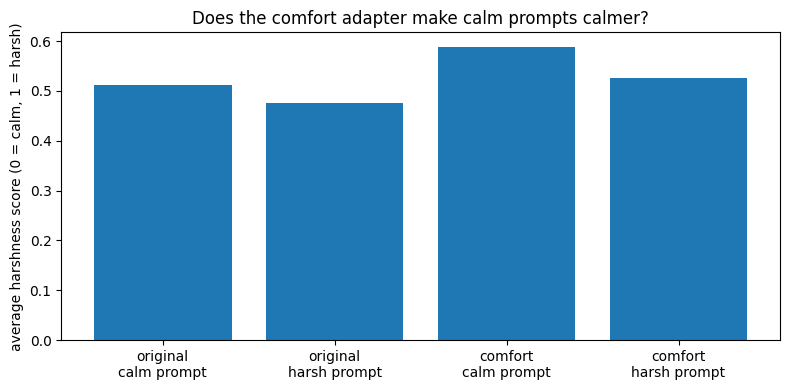

In [46]:
summary = comfort_results.groupby(["model", "tone"])["harshness"].mean()
labels = []
values = []
for model_name in comfort_results.model.unique():
    for tone in ["calm", "harsh"]:
        labels.append(model_name + "\n" + tone + " prompt")
        values.append(summary[(model_name, tone)])

plt.figure(figsize=(8, 4))
plt.bar(labels, values)
plt.ylabel("average harshness score (0 = calm, 1 = harsh)")
plt.title("Does the comfort adapter make calm prompts calmer?")
plt.tight_layout()
plt.show()

#### Test B results: comfort

Average harshness score (0 = calmer than all real clips, 1 = harsher than all of them):

| model | calm prompt | harsh prompt |
|---|---|---|
| original | 0.51 | 0.48 |
| comfort adapter | 0.59 | 0.53 |

- A working comfort control needs the calm prompt to score lower than the harsh prompt. This did not happen for either model: the calm prompt scored slightly higher (harsher) than the harsh prompt.
- The calm clips of the comfort adapter (0.59) are harsher than the calm clips of the original model (0.51). So the adapter did not make calm prompts calmer.
- Calm prompts gave a brighter sound, which is the opposite of what we wanted (spectral centroid 3207 Hz vs 2858 Hz for the adapter, 3581 Hz vs 3006 Hz for the original).
- The generated clips have a dynamic range of only about 5 to 7 dB, while the real clips have about 13 dB (calm) and 22 dB (harsh) on average. The generated sound is much steadier than the real recordings, so this part of the score cannot separate calm from harsh well.

**What it means.** In this experiment the comfort adapter did not work. The harshness score is also only a rough proxy, and it is built from the same numbers as the labels, so part of the failure can come from the measure and the proxy labels and not only from the adapter. Listening tests are still needed before saying more.

###16.Type your own prompt and test the model

Write any text and the model generates it with the original model and with each fine-tuned adapter, using the same random seed. For every clip you get a player, a spectrogram and four numbers (loudness, brightness, crest factor, dynamic range).


Examples to try: `light and gentle rain`, `heavy and strong wind`, `calm and soft thunderstorm`, `harsh and sudden thunderstorm`, `calm and soft, light and gentle ocean waves`.

Prompt: heavy and strong rain | seed: 42
original model


fine-tuned: intensity


fine-tuned: comfort


,model,rms_dbfs,centroid_hz,crest_factor,dynamic_range_db
0,original model,-20.1,3957,5.0,3.1
1,fine-tuned: intensity,-21.0,3855,5.3,2.5
2,fine-tuned: comfort,-21.2,3749,5.1,2.2


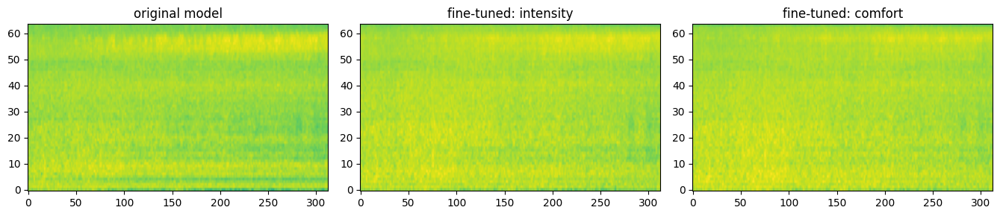

In [47]:
def compare_prompt(prompt, adapters=None, seed=SEED, duration=DURATION_SECONDS):
    if adapters is None:
        adapters = [None] + list(adapter_states.keys())

    rows = []
    clips = []
    names = []
    for adapter in adapters:
        audio = generate_text(prompt, adapter=adapter, seed=seed, duration=duration)
        name = "original model" if adapter is None else "fine-tuned: " + adapter
        clip = clip_features(audio)
        rows.append(dict(model=name, rms_dbfs=round(clip["rms_dbfs"], 1), centroid_hz=round(clip["centroid_hz"]),
                         crest_factor=round(clip["crest_factor"], 1), dynamic_range_db=round(clip["dynamic_range_db"], 1)))
        clips.append(audio)
        names.append(name)

    print("Prompt:", prompt, "| seed:", seed)
    for name, audio in zip(names, clips):
        print(name)
        display(Audio(audio, rate=SR, normalize=False))
    display(pd.DataFrame(rows))

    fig, axes = plt.subplots(1, len(clips), figsize=(4.5 * len(clips), 3), squeeze=False)
    for axis, name, audio in zip(axes[0], names, clips):
        mel = librosa.power_to_db(librosa.feature.melspectrogram(y=audio, sr=SR, n_mels=64), ref=np.max)
        axis.imshow(mel, origin="lower", aspect="auto", vmin=-80, vmax=0)
        axis.set_title(name)
    plt.tight_layout()
    plt.show()
    return clips

MY_PROMPT = "heavy and strong rain"
_ = compare_prompt(MY_PROMPT)

In [48]:
# Set this to True when you want to type prompts. It is False so that "Run all" does not stop at the input box.
RUN_INTERACTIVE_LOOP = False

# Keep typing prompts here. Press Enter on an empty line to stop.
while RUN_INTERACTIVE_LOOP:
    text = input("Prompt (empty line to stop): ").strip()
    if text == "":
        break
    _ = compare_prompt(text)

#### Manual prompt tests

We tried "heavy and strong rain" and "rain nice sound" with seed 42. For both prompts the original model and the two adapters gave very close numbers (first prompt: loudness -20.1 / -21.0 / -21.2 dBFS and spectral centroid 3957 / 3855 / 3749 Hz for original / intensity / comfort). So the adapters change the sound only a little compared with the original model. This fits the small loss drop and the short training (150 steps, rank 8). Two prompts and one seed are only a first look.

###17.Save the adapters

The adapters are small. I save them in `soundscape_export/extra/` so they can be loaded later without training again.

In [49]:
adapter_path = EXTRA / "lora_adapters.pt"
torch.save(adapter_states, adapter_path)
print("Saved adapters:", list(adapter_states), "| file size (MB):", round(adapter_path.stat().st_size / 1e6, 2))

finetune_notes = {"method": "LoRA on AudioLDM 2 U-Net cross-attention (plain PyTorch)",
                  "lora_rank": LORA_RANK, "lora_parts": list(LORA_PARTS), "train_steps": TRAIN_STEPS,
                  "labels": "proxy labels from audio (RMS terciles, harshness score), not human labels",
                  "trained_adapters": list(adapter_states),
                  "validation_loss_before_after": {name: [h["val_loss"][0], h["val_loss"][-1]] for name, h in histories.items()},
                  "listening_review": "not recorded"}
with open(EXTRA / "finetune_notes.json", "w") as f:
    json.dump(finetune_notes, f, indent=2)

Saved adapters: ['intensity', 'comfort'] | file size (MB): 12.91


##18.Why the first results were weak, and what we change

The first experiment ran without errors, but it did not give reliable control. Before changing anything, we list what went wrong and what we do about it.

| What we found | Evidence | What we change in Part 3 |
|---|---|---|
| One seed is too noisy | the medium level was often out of order, even for the original model | use 6 seeds and report mean and spread |
| Labels used all splits | light / heavy and calm / harsh cut points were computed on all 200 clips | cut points from the train clips only |
| Both adapters learned almost the same | same validation loss curve (-3.9% for both) | longer training plus a control adapter trained on shuffled captions |
| Comfort did not work | calm prompts gave a brighter sound, and generated clips are steadier than real ones | direct controls that do not need training: best-of-N selection and a soft filter |
| No human check | no listening data yet | a blind listening pack with rating sheets and a forced-choice test |




##19.Labels without leakage

In the first experiment, the cut points for light / medium / heavy and for calm / harsh were computed with all 200 clips, including the validation and test clips. Here we compute them from the **train clips only** and then apply the same cut points to every clip. This is also how a new clip would be labeled in real use.

###19.1 Intensity labels from train clips only

In [ ]:
train_ft = ft[ft.split == "train"]

# Cut points per class: the 1/3 and 2/3 quantiles of the loudness of the train clips
cut_points = train_ft.groupby("category")["rms_dbfs"].quantile([1 / 3, 2 / 3]).unstack()
cut_points.columns = ["light_to_medium", "medium_to_heavy"]
display(cut_points.round(1))

ft["intensity_v2"] = "medium"
for class_name in CLASSES:
    in_class = ft.category == class_name
    low_cut = cut_points.loc[class_name, "light_to_medium"]
    high_cut = cut_points.loc[class_name, "medium_to_heavy"]
    ft.loc[in_class & (ft.rms_dbfs <= low_cut), "intensity_v2"] = "light"
    ft.loc[in_class & (ft.rms_dbfs > high_cut), "intensity_v2"] = "heavy"

print("Clips per label and split (new labels):")
display(pd.crosstab(ft.split, ft.intensity_v2))
print("Clips whose intensity label changed compared with the first experiment:")
display(pd.crosstab(ft.split, ft.intensity != ft.intensity_v2, rownames=["split"], colnames=["label changed"]))

###19.2 Comfort labels from train clips only

The harshness score of a clip is the average of three percentile ranks (brightness, crest factor, dynamic range). Now each rank is measured against the **train clips of the same class** only. A clip is "harsh" if its score is above the median score of the train clips of its class.

In [ ]:
HARSH_FEATURES = ["centroid_hz", "crest_factor", "dynamic_range_db"]

def harshness_train_only(class_name, clip):
    # 0 = calmer than every train clip of the class, 1 = harsher than every train clip of the class
    parts = []
    for column in HARSH_FEATURES:
        reference = train_ft.loc[train_ft.category == class_name, column]
        parts.append(float((reference < clip[column]).mean()))
    return sum(parts) / len(parts)

ft["harsh_score_v2"] = 0.0
for row_index in ft.index:
    row = ft.loc[row_index]
    ft.loc[row_index, "harsh_score_v2"] = harshness_train_only(row.category, row)

ft["comfort_v2"] = "calm"
for class_name in CLASSES:
    in_class = ft.category == class_name
    middle = ft.loc[in_class & (ft.split == "train"), "harsh_score_v2"].median()
    ft.loc[in_class & (ft.harsh_score_v2 > middle), "comfort_v2"] = "harsh"

print("Clips per label and split (new labels):")
display(pd.crosstab(ft.split, ft.comfort_v2))

# Do the two label sets mix up? Heavy sounds should not simply be the harsh ones.
intensity_number = ft.intensity_v2.map({"light": 0, "medium": 1, "heavy": 2})
print("Spearman correlation between intensity and harshness:", round(float(intensity_number.corr(ft.harsh_score_v2, method="spearman")), 2))

The correlation is negative (about -0.34 on our data). Heavier clips tend to get a lower harshness score, because a dense, continuous sound has a low crest factor. So "heavy" and "calm" are partly mixed in this dataset, and this limits any adapter that uses both kinds of words together.

###19.3 Captions, and a shuffled-caption control

For the second LoRA attempt we need captions again. We also make a **control**: the same train captions, but the intensity words are shuffled between the train clips of the same class (the class word stays correct). If an adapter trained on shuffled captions learns as much as the real one, then its gain does not come from the words.

In [52]:
ft["caption_intensity_v2"] = [INTENSITY_WORDS[i] + " " + CLASS_WORDS[c] for i, c in zip(ft.intensity_v2, ft.category)]
ft["caption_comfort_v2"] = [COMFORT_WORDS[k] + " " + CLASS_WORDS[c] for k, c in zip(ft.comfort_v2, ft.category)]

# Control captions: shuffle the intensity words inside each class, for the train clips only
shuffler = np.random.default_rng(SEED)
ft["caption_shuffled_v2"] = ft["caption_intensity_v2"]
for class_name in CLASSES:
    in_train_class = (ft.category == class_name) & (ft.split == "train")
    ft.loc[in_train_class, "caption_shuffled_v2"] = shuffler.permutation(ft.loc[in_train_class, "caption_intensity_v2"].values)

ft.to_csv(EXTRA / "finetune_labels_v2.csv", index=False)
display(ft[["filename", "split", "caption_intensity_v2", "caption_comfort_v2", "caption_shuffled_v2"]].sample(6, random_state=SEED))

,filename,split,caption_intensity_v2,caption_comfort_v2,caption_shuffled_v2
95,3-136608-A-16.wav,train,moderate wind,harsh and sudden wind,heavy and strong wind
15,1-29532-A-16.wav,train,light and gentle wind,harsh and sudden wind,moderate wind
30,1-54958-A-10.wav,train,heavy and strong rain,calm and soft rain,moderate rain
158,4-195497-B-11.wav,validation,light and gentle ocean waves,harsh and sudden ocean waves,light and gentle ocean waves
128,4-156993-A-19.wav,validation,heavy and strong thunderstorm,harsh and sudden thunderstorm,heavy and strong thunderstorm
115,3-164630-A-11.wav,train,moderate ocean waves,calm and soft ocean waves,light and gentle ocean waves


##20.Noise floor: the original model with 6 seeds

We generate every prompt with 6 different seeds, using the original model. This gives us a normal baseline and also shows **how much the result changes only because of the seed**. An effect smaller than this noise cannot be trusted with one seed.

The generated clips are saved in `soundscape_export/extra/v3/audio`. If the Colab session stops, run the cells again and the saved clips are reused.

In [53]:
V3 = EXTRA / "v3"
V3_AUDIO = V3 / "audio"
V3_AUDIO.mkdir(parents=True, exist_ok=True)

SEEDS_V3 = [42, 43, 44, 45, 46, 47]
CLASSES_V3 = CLASSES          # use a shorter list here to save time, for example ["rain", "wind", "thunderstorm"]
COMFORT_TONES = ["calm", "harsh"]

def prompt_for(category, condition):
    if condition in INTENSITY_WORDS:
        return INTENSITY_WORDS[condition] + " " + CLASS_WORDS[category]
    return COMFORT_WORDS[condition] + " " + CLASS_WORDS[category]

def clip_path(model_name, category, condition, seed):
    return V3_AUDIO / (model_name + "__" + category + "__" + condition + "__" + str(seed) + ".wav")

def get_clip(model_name, category, condition, seed):
    # Return a saved clip, or generate it once and save it (model_name "original" = no adapter)
    path = clip_path(model_name, category, condition, seed)
    if path.exists():
        audio, _ = sf.read(path, dtype="float32")
        return audio
    adapter = None if model_name == "original" else model_name
    audio = generate_text(prompt_for(category, condition), adapter=adapter, seed=seed)
    sf.write(path, audio, SR, subtype="FLOAT")
    return audio

def measure_clip(audio, category):
    clip = clip_features(audio)
    return dict(norm_rms_dbfs=audio_metrics(peak_normalize(audio))["rms_dbfs"],
                harshness=harshness_train_only(category, clip),
                centroid_hz=clip["centroid_hz"], crest_factor=clip["crest_factor"],
                dynamic_range_db=clip["dynamic_range_db"])

def run_grid(model_names, conditions, seeds, categories):
    rows = []
    for model_name in model_names:
        for category in categories:
            for condition in conditions:
                for seed in seeds:
                    audio = get_clip(model_name, category, condition, seed)
                    rows.append(dict(model=model_name, category=category, condition=condition, seed=seed,
                                     **measure_clip(audio, category)))
            print(model_name, category, "done")
    return pd.DataFrame(rows)

real_levels_v2 = ft[ft.split == "train"].groupby(["category", "intensity_v2"])["norm_rms_dbfs"].mean()

In [ ]:
# 5 classes x 3 levels x 6 seeds = 90 clips (about 15-20 minutes on a T4 the first time)
base_int = run_grid(["original"], LEVELS, SEEDS_V3, CLASSES_V3)
base_int.to_csv(V3 / "baseline_intensity.csv", index=False)

In [ ]:
# 5 classes x 2 tones x 6 seeds = 60 clips (about 10-12 minutes the first time)
base_comf = run_grid(["original"], COMFORT_TONES, SEEDS_V3, CLASSES_V3)
base_comf.to_csv(V3 / "baseline_comfort.csv", index=False)

mean  std
category      condition           
pouring_water heavy     -20.5  0.7
              light     -24.5  0.9
              medium    -24.8  0.9
rain          heavy     -20.3  0.4
              light     -23.2  0.9
              medium    -24.7  1.3
sea_waves     heavy     -21.6  1.6
              light     -22.4  1.2
              medium    -22.7  1.1
thunderstorm  heavy     -22.0  1.2
              light     -22.5  0.9
              medium    -25.1  2.6
wind          heavy     -19.5  0.9
              light     -20.5  1.9
              medium    -21.4  3.4

Average seed-to-seed standard deviation: 1.3 dB


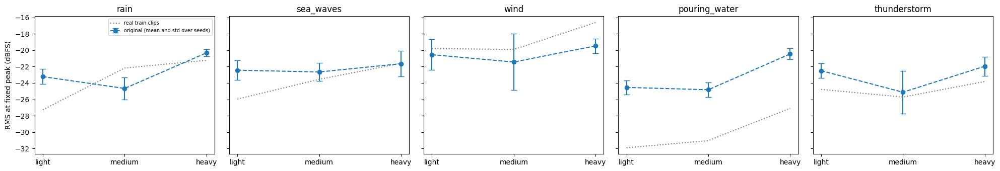

In [56]:
# How much does the intensity measure change only because of the seed?
seed_spread = base_int.groupby(["category", "condition"])["norm_rms_dbfs"].agg(["mean", "std"]).round(1)
display(seed_spread)
print("Average seed-to-seed standard deviation:", round(float(seed_spread["std"].mean()), 1), "dB")

fig, axes = plt.subplots(1, len(CLASSES_V3), figsize=(4 * len(CLASSES_V3), 3.5), sharey=True, squeeze=False)
for axis, class_name in zip(axes[0], CLASSES_V3):
    stats = base_int[base_int.category == class_name].groupby("condition")["norm_rms_dbfs"].agg(["mean", "std"]).loc[LEVELS]
    axis.errorbar(LEVELS, stats["mean"], yerr=stats["std"], fmt="o--", capsize=4, label="original (mean and std over seeds)")
    axis.plot(LEVELS, [real_levels_v2[(class_name, level)] for level in LEVELS], ":", color="gray", label="real train clips")
    axis.set_title(class_name)
axes[0][0].set_ylabel("RMS at fixed peak (dBFS)")
axes[0][0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [57]:
# Does "heavy" come out denser than "light" for the original model, seed by seed?
direction_rows = []
for class_name in CLASSES_V3:
    part = base_int[base_int.category == class_name]
    light = part[part.condition == "light"].set_index("seed")["norm_rms_dbfs"]
    heavy = part[part.condition == "heavy"].set_index("seed")["norm_rms_dbfs"]
    direction_rows.append(dict(category=class_name,
                               generated_change_db=round(float((heavy - light).mean()), 1),
                               real_change_db=round(float(real_levels_v2[(class_name, "heavy")] - real_levels_v2[(class_name, "light")]), 1),
                               seeds_heavy_above_light=str(int((heavy > light).sum())) + " of " + str(len(light))))
display(pd.DataFrame(direction_rows))

# Does the "calm" prompt give a calmer clip than the "harsh" prompt, for the original model?
calm_scores = base_comf[base_comf.condition == "calm"].set_index(["category", "seed"])["harshness"]
harsh_scores = base_comf[base_comf.condition == "harsh"].set_index(["category", "seed"])["harshness"]
print("Average harshness (0 = calm, 1 = harsh): calm prompt", round(float(calm_scores.mean()), 2),
      "| harsh prompt", round(float(harsh_scores.mean()), 2))
print("Pairs (class, seed) where the calm prompt is calmer:", int((calm_scores < harsh_scores).sum()), "of", len(calm_scores))

,category,generated_change_db,real_change_db,seeds_heavy_above_light
0,rain,2.9,6.0,6 of 6
1,sea_waves,0.8,4.4,5 of 6
2,wind,1.1,3.2,5 of 6
3,pouring_water,4.1,4.8,6 of 6
4,thunderstorm,0.5,1.0,4 of 6


Average harshness (0 = calm, 1 = harsh): calm prompt 0.54 | harsh prompt 0.49
Pairs (class, seed) where the calm prompt is calmer: 9 of 30


##21.Controls without training

The 6 seeds give us 6 different clips for every prompt, and they differ in density and in harshness. Instead of taking a random one, we can **choose** the clip that is closest to what was asked (best-of-N). We can also **change** a clip afterwards with a simple filter.



###21.1 Intensity by best-of-N selection

For every class and level, the target is the average density (RMS at a fixed peak) of the real train clips with that label. From the 6 generated clips we keep the one closest to the target.

In [58]:
selected_levels = {}
selection_rows = []
for class_name in CLASSES_V3:
    for level in LEVELS:
        pool = base_int[(base_int.category == class_name) & (base_int.condition == level)]
        target = real_levels_v2[(class_name, level)]
        gaps = (pool.norm_rms_dbfs - target).abs()
        best = pool.loc[gaps.idxmin()]
        selected_levels[(class_name, level)] = int(best.seed)
        selection_rows.append(dict(category=class_name, level=level, target_db=round(float(target), 1),
                                   random_error_db=round(float(gaps.mean()), 1),
                                   selected_error_db=round(float(gaps.min()), 1),
                                   selected_seed=int(best.seed)))
selection_table = pd.DataFrame(selection_rows)
display(selection_table)
print("Average distance to the target: random seed", round(selection_table.random_error_db.mean(), 1), "dB | selected", round(selection_table.selected_error_db.mean(), 1), "dB")

# Side check with measures that were NOT used for the selection: does heavy also become brighter or spikier?
side_rows = []
for class_name in CLASSES_V3:
    light_clip = base_int[(base_int.category == class_name) & (base_int.condition == "light") & (base_int.seed == selected_levels[(class_name, "light")])].iloc[0]
    heavy_clip = base_int[(base_int.category == class_name) & (base_int.condition == "heavy") & (base_int.seed == selected_levels[(class_name, "heavy")])].iloc[0]
    side_rows.append(dict(category=class_name, norm_rms_change_db=round(float(heavy_clip.norm_rms_dbfs - light_clip.norm_rms_dbfs), 1),
                          centroid_change_hz=round(float(heavy_clip.centroid_hz - light_clip.centroid_hz)),
                          dynamic_range_change_db=round(float(heavy_clip.dynamic_range_db - light_clip.dynamic_range_db), 1)))
display(pd.DataFrame(side_rows))

,category,level,target_db,random_error_db,selected_error_db,selected_seed
0,rain,light,-27.3,4.0,2.8,44
1,rain,medium,-22.2,2.5,1.1,42
2,rain,heavy,-21.2,0.9,0.4,43
3,sea_waves,light,-26.0,3.5,1.5,43
4,sea_waves,medium,-23.6,1.2,0.6,47
5,sea_waves,heavy,-21.6,1.0,0.1,46
6,wind,light,-19.8,1.5,0.5,43
7,wind,medium,-19.9,3.3,1.9,46
8,wind,heavy,-16.6,2.9,1.4,42
9,pouring_water,light,-31.9,7.4,6.2,43


Average distance to the target: random seed 3.1 dB | selected 1.9 dB


,category,norm_rms_change_db,centroid_change_hz,dynamic_range_change_db
0,rain,3.7,-185,-1.4
1,sea_waves,2.8,-375,-0.2
2,wind,2.3,-1292,-0.3
3,pouring_water,4.2,-287,-4.5
4,thunderstorm,-0.1,-666,4.1


###21.2 Comfort by best-of-N selection

For the "calm and soft" prompt we keep the clip with the lowest harshness score out of the 6 seeds.

,harsh_prompt_mean,calm_prompt_mean,calm_selected,selected_seed
category,,,,
rain,0.47,0.62,0.53,43
sea_waves,0.57,0.69,0.60,47
wind,0.64,0.65,0.60,42
pouring_water,0.32,0.38,0.33,47
thunderstorm,0.42,0.37,0.33,42


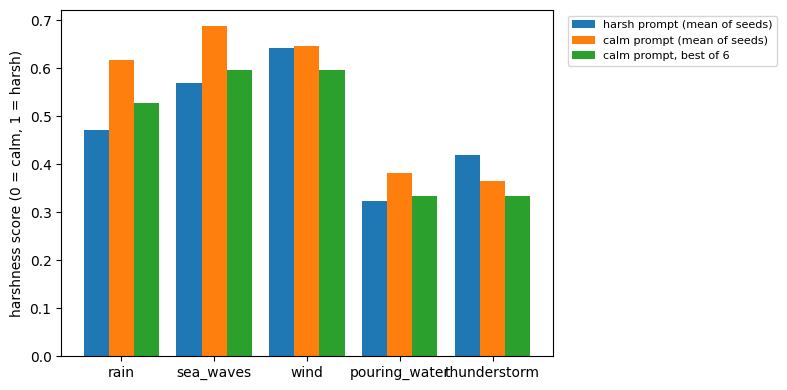

In [59]:
calm_pool = base_comf[base_comf.condition == "calm"]
harsh_pool = base_comf[base_comf.condition == "harsh"]
selected_calm = calm_pool.loc[calm_pool.groupby("category")["harshness"].idxmin()].set_index("category")

comfort_selection = pd.DataFrame({
    "harsh_prompt_mean": harsh_pool.groupby("category")["harshness"].mean(),
    "calm_prompt_mean": calm_pool.groupby("category")["harshness"].mean(),
    "calm_selected": selected_calm["harshness"],
    "selected_seed": selected_calm["seed"]}).loc[CLASSES_V3]
display(comfort_selection.round(2))

plt.figure(figsize=(8, 4))
x_positions = np.arange(len(CLASSES_V3))
plt.bar(x_positions - 0.27, comfort_selection.harsh_prompt_mean, width=0.27, label="harsh prompt (mean of seeds)")
plt.bar(x_positions, comfort_selection.calm_prompt_mean, width=0.27, label="calm prompt (mean of seeds)")
plt.bar(x_positions + 0.27, comfort_selection.calm_selected, width=0.27, label="calm prompt, best of 6")
plt.xticks(x_positions, CLASSES_V3)
plt.ylabel("harshness score (0 = calm, 1 = harsh)")
plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

###21.3 Comfort with a soft filter

The first experiment showed that the generated sound is brighter and steadier than the real recordings. A simple fix is a **soft filter** with one strength knob from 0 to 1:

1. a low-pass filter that removes the high frequencies (cut-off from 7.5 kHz at strength 0 down to 2.5 kHz at strength 1)
2. a gentle peak limiter that bends the highest peaks
3. the loudness is set back to the loudness of the input, so only the character changes

A strong filter can make the sound dull, and that is something only listening can judge. The table shows what the knob does to the measures.

In [60]:
from scipy.signal import butter, sosfiltfilt

def soften(audio, strength):
    # strength 0 = unchanged, 1 = strongest softening
    if strength <= 0:
        return audio
    cutoff = 7500 - strength * (7500 - 2500)
    filter_sos = butter(4, cutoff, btype="low", fs=SR, output="sos")
    filtered = sosfiltfilt(filter_sos, audio)

    # gentle limiter: a tanh curve that bends the peaks
    knee = (np.max(np.abs(filtered)) + 1e-8) * (1.0 - 0.5 * strength)
    limited = knee * np.tanh(filtered / knee)

    # same loudness as the input
    gain = np.sqrt(np.mean(audio ** 2) + 1e-12) / (np.sqrt(np.mean(limited ** 2)) + 1e-12)
    return np.clip(limited * gain, -1.0, 1.0).astype(np.float32)

STRENGTHS = [0.0, 0.25, 0.5, 0.75, 1.0]
soft_rows = []
for class_name in CLASSES_V3:
    source = get_clip("original", class_name, "calm", int(selected_calm.loc[class_name, "seed"]))
    for strength in STRENGTHS:
        clip = clip_features(soften(source, strength))
        soft_rows.append(dict(category=class_name, strength=strength, harshness=harshness_train_only(class_name, clip),
                              centroid_hz=clip["centroid_hz"], crest_factor=clip["crest_factor"],
                              dynamic_range_db=clip["dynamic_range_db"]))
soft_table = pd.DataFrame(soft_rows)
display(soft_table.groupby("strength")[["harshness", "centroid_hz", "crest_factor", "dynamic_range_db"]].mean().round(2))

,harshness,centroid_hz,crest_factor,dynamic_range_db
strength,,,,
0.00,0.48,3425.21,5.82,5.59
0.25,0.39,2928.74,4.37,5.29
0.50,0.28,2191.15,4.40,5.88
0.75,0.22,1499.26,4.06,6.42
1.00,0.13,1061.28,3.44,6.39


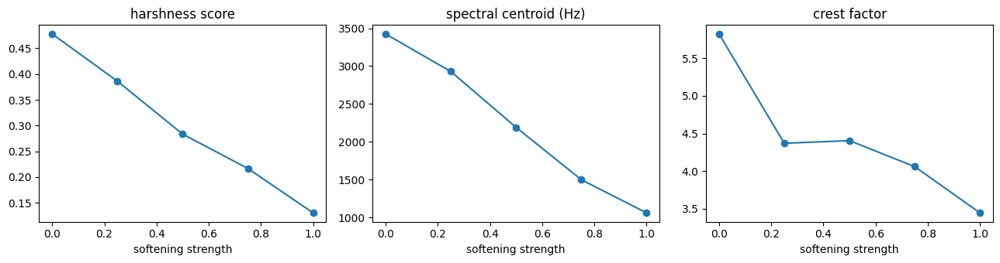

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for axis, column, title in zip(axes, ["harshness", "centroid_hz", "crest_factor"],
                                ["harshness score", "spectral centroid (Hz)", "crest factor"]):
    averages = soft_table.groupby("strength")[column].mean()
    axis.plot(averages.index, averages.values, "o-")
    axis.set_xlabel("softening strength")
    axis.set_title(title)
plt.tight_layout()
plt.show()

##22.Second LoRA attempt

Same method as before (plain PyTorch LoRA on the cross-attention layers), with these changes:

- labels and captions from section 19 (train-only cut points)
- 300 steps instead of 150 and a learning rate of 2e-4 instead of 1e-4, because the first adapters changed the sound very little
- a third adapter trained on **shuffled captions**, as a control

We train the three adapters one after the other and save the weights after each one. Each takes about 15 minutes on a T4 (the first 150 steps took about 8). Set `RUN_LORA_V2 = False` to skip this section.

In [62]:
RUN_LORA_V2 = True
V2_STEPS = 3000
V2_LEARNING_RATE = 2e-4
V2_ADAPTERS = {"intensity_v2": "caption_intensity_v2",
               "comfort_v2": "caption_comfort_v2",
               "shuffled_v2": "caption_shuffled_v2"}

histories_v2 = {}
if RUN_LORA_V2:
    if DEVICE == "cuda":
        gc.collect()
        torch.cuda.empty_cache()
    for adapter_name, column in V2_ADAPTERS.items():
        ADAPTER_CAPTIONS[adapter_name] = column
        if adapter_name in adapter_states:
            print("Adapter", adapter_name, "is already trained, skipping it.")
            continue
        print("=" * 70)
        print("Training adapter:", adapter_name, "| example caption:", ft[column].iloc[0])
        histories_v2[adapter_name] = train_adapter(column, steps=V2_STEPS, learning_rate=V2_LEARNING_RATE, check_every=50)
        adapter_states[adapter_name] = get_lora_state()
        torch.save(adapter_states, EXTRA / "lora_adapters.pt")      # saved after every adapter, in case Colab stops
    use_adapter(None)
    print("Trained adapters:", list(adapter_states))

Training adapter: intensity_v2 | example caption: light and gentle thunderstorm
step    0 | validation loss 0.0526 (before training)
step   50 | train loss 0.1017 | validation loss 0.051 | 2.4 min
step  100 | train loss 0.0796 | validation loss 0.0504 | 4.4 min
step  150 | train loss 0.0689 | validation loss 0.0504 | 6.4 min
step  200 | train loss 0.0834 | validation loss 0.0503 | 8.4 min
step  250 | train loss 0.0791 | validation loss 0.0503 | 10.4 min
step  300 | train loss 0.0854 | validation loss 0.0503 | 12.4 min
Training adapter: comfort_v2 | example caption: harsh and sudden thunderstorm
step    0 | validation loss 0.0526 (before training)
step   50 | train loss 0.1016 | validation loss 0.051 | 2.0 min
step  100 | train loss 0.0796 | validation loss 0.0504 | 4.0 min
step  150 | train loss 0.0689 | validation loss 0.0504 | 6.0 min
step  200 | train loss 0.0834 | validation loss 0.0503 | 7.9 min
step  250 | train loss 0.0791 | validation loss 0.0503 | 9.9 min
step  300 | train los

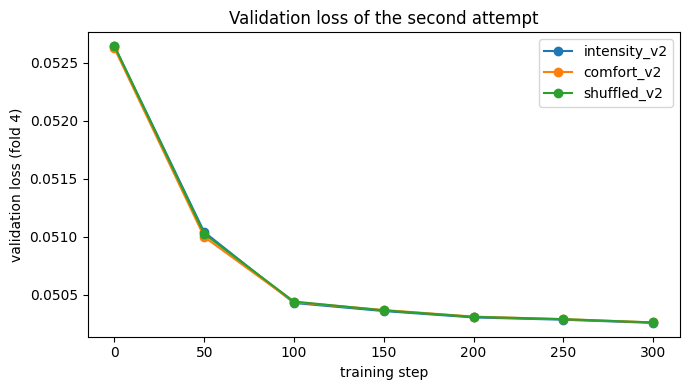

,adapter,val_before,val_after,test_original,test_adapter,test_change_percent
0,intensity_v2,0.0526,0.0503,0.0552,0.0523,-5.2393
1,comfort_v2,0.0526,0.0503,0.0549,0.0523,-4.7477
2,shuffled_v2,0.0526,0.0503,0.0552,0.0523,-5.2281


In [63]:
if len(histories_v2) > 0:
    plt.figure(figsize=(7, 4))
    for adapter_name, history in histories_v2.items():
        plt.plot(history["val_step"], history["val_loss"], "o-", label=adapter_name)
    plt.xlabel("training step")
    plt.ylabel("validation loss (fold 4)")
    plt.title("Validation loss of the second attempt")
    plt.legend()
    plt.tight_layout()
    plt.show()

    loss_rows = []
    for adapter_name in histories_v2:
        column = V2_ADAPTERS[adapter_name]
        use_adapter(None)
        original_test = validation_loss(column, split="test")
        use_adapter(adapter_name)
        tuned_test = validation_loss(column, split="test")
        loss_rows.append(dict(adapter=adapter_name,
                              val_before=histories_v2[adapter_name]["val_loss"][0],
                              val_after=histories_v2[adapter_name]["val_loss"][-1],
                              test_original=original_test, test_adapter=tuned_test))
    use_adapter(None)
    loss_table = pd.DataFrame(loss_rows)
    loss_table["test_change_percent"] = 100 * (loss_table.test_adapter - loss_table.test_original) / loss_table.test_original
    display(loss_table.round(4))
else:
    print("No new adapter was trained in this session.")

In [ ]:
# Generation test of the second attempt: 3 seeds, same prompts as for the original model
ADAPTER_SEEDS = SEEDS_V3[:3]
adapter_results = []
if "intensity_v2" in adapter_states:
    adapter_results.append(run_grid(["intensity_v2"], LEVELS, ADAPTER_SEEDS, CLASSES_V3))
if "comfort_v2" in adapter_states:
    adapter_results.append(run_grid(["comfort_v2"], COMFORT_TONES, ADAPTER_SEEDS, CLASSES_V3))

all_results = pd.concat([base_int, base_comf] + adapter_results, ignore_index=True)
all_results.to_csv(V3 / "all_results.csv", index=False)
print("Rows:", len(all_results))

In [ ]:
# Same seeds for every model, so the comparison is fair
fair = all_results[all_results.seed.isin(ADAPTER_SEEDS)]

intensity_rows = []
for model_name in ["original", "intensity_v2"]:
    part = fair[(fair.model == model_name) & fair.condition.isin(LEVELS)]
    if len(part) == 0:
        continue
    changes = []
    for class_name in CLASSES_V3:
        light = part[(part.category == class_name) & (part.condition == "light")].set_index("seed")["norm_rms_dbfs"]
        heavy = part[(part.category == class_name) & (part.condition == "heavy")].set_index("seed")["norm_rms_dbfs"]
        real_change = real_levels_v2[(class_name, "heavy")] - real_levels_v2[(class_name, "light")]
        changes.append(dict(change=float((heavy - light).mean()), gap_to_real=abs(float((heavy - light).mean()) - float(real_change)),
                            seeds_up=int((heavy > light).sum()), seeds=len(light)))
    changes = pd.DataFrame(changes)
    intensity_rows.append(dict(model=model_name, mean_heavy_minus_light_db=round(changes.change.mean(), 1),
                               mean_gap_to_real_db=round(changes.gap_to_real.mean(), 1),
                               heavy_above_light=str(int(changes.seeds_up.sum())) + " of " + str(int(changes.seeds.sum()))))
print("Intensity (3 seeds, all classes):")
display(pd.DataFrame(intensity_rows))

comfort_rows = []
for model_name in ["original", "comfort_v2"]:
    part = fair[(fair.model == model_name) & fair.condition.isin(COMFORT_TONES)]
    if len(part) == 0:
        continue
    calm = part[part.condition == "calm"].set_index(["category", "seed"])["harshness"]
    harsh = part[part.condition == "harsh"].set_index(["category", "seed"])["harshness"]
    comfort_rows.append(dict(model=model_name, calm_prompt=round(float(calm.mean()), 2), harsh_prompt=round(float(harsh.mean()), 2),
                             calm_calmer_than_harsh=str(int((calm < harsh).sum())) + " of " + str(len(calm))))
print("Comfort (3 seeds, all classes):")
display(pd.DataFrame(comfort_rows))

##23.Blind listening test

The measures above are rough proxies. What matters for a relaxation sound is what people hear, so this section builds a **listening pack**:

- **Rating clips:** for every class, four versions of the "calm and soft" sound: the original model, the best-of-6 clip, the best-of-6 clip with the soft filter, and the comfort adapter (if it was trained). Raters give 1-5 scores for naturalness, category match, comfort, artifact-free and continuity (the same columns as `listening_ratings_template.csv` in the GitHub repo).
- **Intensity pairs:** for every class and method, a "light" and a "heavy" clip in random order. The rater only says which one sounds heavier. This forced choice is easier to answer than a score.

All clips get a random name, are set to the same loudness, and every reviewer gets the clips in a different order. The key that says which clip is which stays in a separate secret file.

In [ ]:
SOFTEN_STRENGTH = 0.5
N_REVIEWERS = 5
PACK = V3 / "listening_pack"
PACK.mkdir(parents=True, exist_ok=True)

pack_random = np.random.default_rng(2026)
used_ids = set()

def new_blind_id():
    while True:
        blind_id = "c" + format(int(pack_random.integers(0, 16 ** 6)), "06x")
        if blind_id not in used_ids:
            used_ids.add(blind_id)
            return blind_id

def match_loudness(audio, target_rms=0.07):
    scaled = audio * (target_rms / (np.sqrt(np.mean(audio ** 2)) + 1e-12))
    peak = np.max(np.abs(scaled))
    if peak > 0.95:
        scaled = scaled * (0.95 / peak)
    return scaled.astype(np.float32)

def save_blind_clip(audio):
    blind_id = new_blind_id()
    sf.write(PACK / (blind_id + ".wav"), match_loudness(audio), SR, subtype="PCM_16")
    return blind_id

# A. Rating clips (comfort)
rating_key_rows = []
for class_name in CLASSES_V3:
    best_seed = int(selected_calm.loc[class_name, "seed"])
    variants = {"original": get_clip("original", class_name, "calm", SEEDS_V3[0]),
                "selected": get_clip("original", class_name, "calm", best_seed)}
    variants["selected_softened"] = soften(variants["selected"], SOFTEN_STRENGTH)
    if "comfort_v2" in adapter_states:
        variants["comfort_adapter"] = get_clip("comfort_v2", class_name, "calm", SEEDS_V3[0])
    for variant, audio in variants.items():
        rating_key_rows.append(dict(blind_id=save_blind_clip(audio), category=class_name, variant=variant))
rating_key = pd.DataFrame(rating_key_rows)

# B. Intensity pairs (light versus heavy), the heavier clip is in a random position
pair_key_rows = []
pair_number = 0
for class_name in CLASSES_V3:
    methods = {"original": (get_clip("original", class_name, "light", SEEDS_V3[0]),
                            get_clip("original", class_name, "heavy", SEEDS_V3[0])),
               "selected": (get_clip("original", class_name, "light", selected_levels[(class_name, "light")]),
                            get_clip("original", class_name, "heavy", selected_levels[(class_name, "heavy")]))}
    if "intensity_v2" in adapter_states:
        methods["intensity_adapter"] = (get_clip("intensity_v2", class_name, "light", SEEDS_V3[0]),
                                        get_clip("intensity_v2", class_name, "heavy", SEEDS_V3[0]))
    for method, (light_audio, heavy_audio) in methods.items():
        pair_number += 1
        light_id = save_blind_clip(light_audio)
        heavy_id = save_blind_clip(heavy_audio)
        heavy_first = bool(pack_random.integers(0, 2))
        pair_key_rows.append(dict(pair_id="p" + str(pair_number).zfill(2), category=class_name, method=method,
                                  clip_A=heavy_id if heavy_first else light_id,
                                  clip_B=light_id if heavy_first else heavy_id,
                                  heavier_is="A" if heavy_first else "B"))
pair_key = pd.DataFrame(pair_key_rows)

rating_key.to_csv(V3 / "listening_key_ratings_SECRET.csv", index=False)
pair_key.to_csv(V3 / "listening_key_pairs_SECRET.csv", index=False)
print("Rating clips:", len(rating_key), "| intensity pairs:", len(pair_key))
display(rating_key.variant.value_counts())

In [ ]:
# One rating sheet and one pairs sheet per reviewer, each in a different random order
RATING_COLUMNS = ["naturalness_1_to_5", "category_match_1_to_5", "comfort_1_to_5", "artifact_free_1_to_5", "continuity_1_to_5"]

for reviewer in range(1, N_REVIEWERS + 1):
    reviewer_id = "R" + str(reviewer)
    sheet = rating_key[["blind_id", "category"]].sample(frac=1, random_state=reviewer).rename(columns={"blind_id": "blind_sample_id"})
    sheet.insert(0, "reviewer_id", reviewer_id)
    sheet["seed"] = ""
    for column in RATING_COLUMNS:
        sheet[column] = ""
    sheet["notes"] = ""
    sheet.to_csv(PACK / ("ratings_" + reviewer_id + ".csv"), index=False)

    pairs_sheet = pair_key[["pair_id", "category", "clip_A", "clip_B"]].sample(frac=1, random_state=100 + reviewer)
    pairs_sheet.insert(0, "reviewer_id", reviewer_id)
    pairs_sheet["answer_heavier_A_or_B"] = ""
    pairs_sheet["notes"] = ""
    pairs_sheet.to_csv(PACK / ("pairs_" + reviewer_id + ".csv"), index=False)

with open(PACK / "README_for_raters.txt", "w") as f:
    f.write("Listening test for SoundScape AI\n\n"
            "Use headphones and keep the same volume for all clips.\n"
            "1) ratings_R*.csv: listen to every clip (file name = blind_sample_id.wav) and give 1-5 scores\n"
            "   (5 = best) for naturalness, category match (does it sound like the category?), comfort (relaxing?),\n"
            "   artifact_free (no clicks, metallic or muffled sound) and continuity (steady, no jumps).\n"
            "2) pairs_R*.csv: listen to clip_A and clip_B and write A or B in answer_heavier_A_or_B for the one\n"
            "   that sounds heavier / denser / stronger. Always choose one.\n"
            "Do not try to guess which clip comes from which method. Send the filled csv file back.\n")

import zipfile
with zipfile.ZipFile(V3 / "listening_pack.zip", "w", zipfile.ZIP_DEFLATED) as pack_zip:
    for path in sorted(PACK.glob("*")):
        pack_zip.write(path, arcname=path.name)
print("Listening pack ready:", V3 / "listening_pack.zip", "(the secret key files are NOT inside it)")

# To download in Colab:
# from google.colab import files
# files.download(str(V3 / "listening_pack.zip"))

## 24. Conclusion

This project explored two related aspects of environmental audio generation: building a pipeline for generating and preparing nature sounds, and investigating whether a pretrained text-to-audio model could be adapted to control their perceptual characteristics.

The generation pipeline used AudioLDM 2 to produce environmental audio for five categories: rain, sea waves, wind, flowing water, and thunderstorm. Generated clips went through candidate selection, audio processing, and quality checks before being assembled into 60-second sound layers. The final exports passed the automated validation checks for duration, silence, and clipping.

Alongside the generation pipeline, we investigated whether LoRA fine-tuning could improve control over two perceptual dimensions: **intensity** (light, moderate, and heavy) and **comfort** (calm and harsh). Since ESC-50 does not provide labels for these attributes, we derived experimental labels from audio characteristics and used them to adapt AudioLDM 2.

The experiments were conducted in two stages. The initial adapters were trained for 150 steps, followed by an extended experiment with 300 training steps and a shuffled-caption control. Although validation and test losses decreased across the experiments, the results did not establish that the model had learned the intended text-audio relationships. In particular, the similar loss reductions observed with shuffled captions raised questions about whether the improvement came from the caption meaning or from general adaptation to the audio data.

The evaluation also showed limitations in perceptual control. In the initial intensity experiment, the adapter did not produce a closer match to the real audio measurements than the original model. In the extended evaluation, the original model moved in the expected direction in 13 out of 15 comparisons, while Intensity V2 did so in 12 out of 15. The comfort experiments also did not establish a reliable distinction between calm and harsh outputs.

These results highlight an important distinction: **a reduction in training loss does not necessarily mean that a generative model has learned the intended behavior.** Evaluating text-to-audio adaptation requires examining the generated audio itself, rather than relying on loss values alone.

Further work could investigate the quality of the derived labels through structured listening evaluations, evaluate adapted models across multiple random seeds, and explore richer audio-text supervision with a larger and more diverse dataset. These steps would help determine whether the limitations come from the training data, the labeling approach, or the adaptation method.

Overall, the project produced a working environmental audio generation pipeline and an experimental investigation into text-guided perceptual control. While the pipeline successfully generated and prepared the sound layers, reliable prompt-based control over intensity and comfort remains an open research question.